# Seclusion EDA — CRDC 2015-16 (school level)
**Task:** explore the cleaned 2015-16 CRDC data to understand seclusion patterns, data completeness, and how school characteristics, staffing and student population relate to seclusion; agree a target definition and feature shortlist. This is the 2015-16 counterpart of the 2017-18 notebook and uses the same structure so results can be compared.

**Inputs:** `crdc_2015_16_analysis_ready.csv` (output of `clean_crdc_2015_16.py`; 96,360 schools x 168 columns). For the cross-year section, `schools_201718_analysis.csv` is also read.

**What differs from 2017-18:** this file has restraint counts (mechanical / physical) and students secluded by sex, so the leakage check and part of the equity check *can* be done; it has no virtual-school indicator and no race breakdown; there is no `flag_analysis_ready`, so the analysis-ready subset is derived here (`~flag_rate_undefined`).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60); pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', context='notebook')

DATA_DIR = Path('/mnt/user-data/uploads')   # <- change to the repo data folder
ID = {'COMBOKEY': str, 'LEAID': str, 'SCHID': str, 'COMBOKEY_stored': str}
raw = pd.read_csv(DATA_DIR/'crdc_2015_16_analysis_ready.csv', low_memory=False, dtype=ID)
print('raw cleaned file:', raw.shape)

raw cleaned file: (96360, 168)

## 0. Harmonise column names
Rename to the 2017-18 schema so identical code and thresholds can be used. Two derived choices are made here and documented as data issues: `grade_band` is derived from the `SCH_GRADE_*` flags (the 2017-18 file ships its own), and impossible shares above 100% are set to NA.

In [2]:
g = lambda c: raw[c]
grades = ['PS','KG']+[f'G{i:02d}' for i in range(1, 13)]
yes = lambda cols: np.column_stack([raw[f'SCH_GRADE_{c}'].eq('Yes') for c in cols]).any(axis=1)
e, m, h = yes(['PS','KG']+[f'G{i:02d}' for i in range(1, 6)]), yes([f'G{i:02d}' for i in range(6, 9)]), yes([f'G{i:02d}' for i in range(9, 13)])
grade_band = np.select([e&~m&~h, m&~e&~h, h&~e&~m, e|m|h], ['elementary','middle','high','span'], 'other')

full = pd.DataFrame({
 'year': g('year'), 'combokey': g('COMBOKEY'), 'leaid': g('LEAID'), 'schid': g('SCHID'), 'lea_state': g('LEA_STATE'),
 'sch_name': g('SCH_NAME'), 'lea_name': g('LEA_NAME'), 'jj': g('JJ'),
 'seclusion_instances_wodis': g('SCH_RSINSTANCES_SECL_WODIS'), 'seclusion_instances_idea': g('SCH_RSINSTANCES_SECL_IDEA'),
 'seclusion_instances_504': g('SCH_RSINSTANCES_SECL_504'), 'seclusion_instances': g('seclusion_instances'),
 'enrollment_total': g('enrollment'), 'enr_idea': g('idea_n'), 'enr_504': g('sec504_n'), 'enr_el': g('lep_n'),
 'seclusion_rate': g('seclusion_rate_per_100'),
 'sch_status_sped': g('SCH_STATUS_SPED'), 'sch_status_charter': g('SCH_STATUS_CHARTER'), 'sch_status_alt': g('SCH_STATUS_ALT'), 'sch_status_magnet': g('SCH_STATUS_MAGNET'),
 'grade_band': grade_band,
 'fte_teachers': g('SCH_FTETEACH_TOT'), 'fte_counselors': g('SCH_FTECOUNSELORS'), 'fte_nurses': g('SCH_FTESERVICES_NUR'),
 'fte_psych': g('SCH_FTESERVICES_PSY'), 'fte_social': g('SCH_FTESERVICES_SOC'), 'fte_leo': g('SCH_FTESECURITY_LEO'), 'fte_guards': g('SCH_FTESECURITY_GUA'),
 'pct_idea': g('idea_share')*100, 'pct_504': g('sec504_share')*100, 'pct_el': g('lep_share')*100,
 'lea_enrollment': g('LEA_ENR'), 'lea_schools': g('LEA_SCHOOLS'),
 'flag_missing_seclusion': g('flag_missing_seclusion'), 'flag_missing_enrollment': g('flag_missing_enrollment'),
 'flag_small_enrollment': g('flag_small_enrollment'), 'flag_fte_outlier': g('flag_fte_outlier'), 'flag_analysis_ready': ~g('flag_rate_undefined'),
})
n_share_gt100 = {c: int((full[c] > 100).sum()) for c in ['pct_idea','pct_504','pct_el']}
for c in ['pct_idea','pct_504','pct_el']: full.loc[full[c] > 100, c] = np.nan   # impossible shares -> NA
ana = full[full.flag_analysis_ready].copy()
print('shares > 100% set to NA:', n_share_gt100)
print('grade_band (derived):', full.grade_band.value_counts().to_dict())
print('full', full.shape, '| analysis-ready', ana.shape)

shares > 100% set to NA: {'pct_idea': 299, 'pct_504': 0, 'pct_el': 18}
grade_band (derived): {'elementary': 37292, 'span': 28929, 'high': 16787, 'middle': 12896, 'other': 456}
full (96360, 39) | analysis-ready (93966, 39)

## 1. Load and validate (checklist 1)
The cleaning script encodes the expected 2015-16 counts from `data_audit.md` (`print_audit_checks`). They are re-checked here against the file, plus internal consistency tests.

In [3]:
expected = {'n_schools': 96360, 'unique_combokey': 96360, 'jj_yes': 608, 'seclusion_all_three_valid': 93966, 'wodis_neg9': 1806, 'wodis_neg5': 588,
            'wodis_positive': 1876, 'idea_positive': 4489, 'enr_m_usable': 96359, 'enr_m_zero': 259, 'enr_sum_zero': 0}
observed = {'n_schools': len(raw), 'unique_combokey': raw.COMBOKEY.nunique(), 'jj_yes': int(raw.flag_jj.sum()), 'seclusion_all_three_valid': int(raw.seclusion_instances.notna().sum()),
            'wodis_neg9': int((raw.SCH_RSINSTANCES_SECL_WODIS_code == -9).sum()), 'wodis_neg5': int((raw.SCH_RSINSTANCES_SECL_WODIS_code == -5).sum()),
            'wodis_positive': int((raw.SCH_RSINSTANCES_SECL_WODIS > 0).sum()), 'idea_positive': int((raw.SCH_RSINSTANCES_SECL_IDEA > 0).sum()),
            'enr_m_usable': int(raw.TOT_ENR_M.notna().sum()), 'enr_m_zero': int((raw.TOT_ENR_M == 0).sum()), 'enr_sum_zero': int((raw.enrollment == 0).sum())}
audit = pd.DataFrame({'expected': expected, 'observed': observed}); audit['match'] = audit.expected == audit.observed
audit

,expected,observed,match
n_schools,96360,96360,True
unique_combokey,96360,96360,True
jj_yes,608,608,True
seclusion_all_three_valid,93966,93966,True
wodis_neg9,1806,1806,True
wodis_neg5,588,588,True
wodis_positive,1876,1876,True
idea_positive,4489,4489,True
enr_m_usable,96359,96359,True
enr_m_zero,259,259,True


In [4]:
comp3 = ['SCH_RSINSTANCES_SECL_WODIS','SCH_RSINSTANCES_SECL_IDEA','SCH_RSINSTANCES_SECL_504']
checks = {
 'years present': raw.year.unique().tolist(),
 'COMBOKEY unique / 12 chars': (bool(raw.COMBOKEY.is_unique), bool(raw.COMBOKEY.str.len().eq(12).all())),
 'COMBOKEY == LEAID + SCHID': bool((raw.COMBOKEY == raw.LEAID + raw.SCHID).all()),
 'seclusion_instances == sum of 3 components (max abs diff)': float((raw.seclusion_instances - raw[comp3].sum(axis=1, min_count=3)).abs().max()),
 'rate == instances/enrollment*100 (max abs diff)': float((raw.seclusion_rate_per_100 - raw.seclusion_instances/raw.enrollment*100).abs().max()),
 'flag_rate_undefined == missing_secl | missing_enr | zero_enr': bool((raw.flag_rate_undefined == (raw.flag_missing_seclusion|raw.flag_missing_enrollment|raw.flag_zero_enrollment)).all()),
 'rows in file / analysis-ready (derived)': (len(raw), int(full.flag_analysis_ready.sum())),
 'stored COMBOKEY still in file, rows in scientific notation': (int(raw.COMBOKEY_stored.str.contains('E', na=False).sum())),
 'states / districts': (full.lea_state.nunique(), full.leaid.nunique()),
}
pd.Series(checks, name='result').to_frame()

,result
years present,[2015-16]
COMBOKEY unique / 12 chars,"(True, True)"
COMBOKEY == LEAID + SCHID,True
seclusion_instances == sum of 3 components (max abs diff),0.000
rate == instances/enrollment*100 (max abs diff),0.000
flag_rate_undefined == missing_secl | missing_enr | zero_enr,True
rows in file / analysis-ready (derived),"(96360, 93966)"
"stored COMBOKEY still in file, rows in scientific notation",78034
states / districts,"(51, 17337)"


In [5]:
dead_flags = [c for c in raw.columns if c.startswith('flag_') and raw[c].dtype == bool and raw[c].sum() == 0]
print('Flags that never fire:', dead_flags)
print('Columns that are 100% empty (excluding _code/_reason helpers):', [c for c in raw.columns if raw[c].isna().all() and not c.endswith(('_code','_reason'))])
print('\nFlag counts (raw file):'); print(raw.filter(like='flag_').sum().to_string())
print('\nReserved-code reasons for the seclusion outcome:'); print(raw.seclusion_reason.value_counts(dropna=False).to_string())
print('\nNote: there is no virtual-school indicator in 2015-16; sch name proxy is used in section 5.')

Flags that never fire: ['flag_zero_enrollment']
Columns that are 100% empty (excluding _code/_reason helpers): []

Flag counts (raw file):
flag_missing_seclusion      2394
flag_missing_enrollment        1
flag_zero_enrollment           0
flag_rate_undefined         2394
flag_fte_placeholder_999       1
flag_fte_outlier             483
flag_jj                      608
flag_sped                   2121
flag_charter                6822
flag_alt                    3294
flag_magnet                 3668
flag_small_enrollment       5579

Reserved-code reasons for the seclusion outcome:
seclusion_reason
NaN                93966
structural_skip     1806
missing              588

Note: there is no virtual-school indicator in 2015-16; sch name proxy is used in section 5.

## 2. Missing values (checklist 2)
One school year in this file. Seclusion is missing when any of the three component counts is a reserved code (set to NA by cleaning).

In [6]:
miss = pd.DataFrame({'n_missing': full.isna().sum(), 'pct_missing': full.isna().mean()*100})
miss = miss[miss.n_missing > 0].sort_values('pct_missing', ascending=False)
miss

,n_missing,pct_missing
fte_leo,70937,73.617
pct_idea,10496,10.892
enr_idea,10197,10.582
seclusion_instances_wodis,2394,2.484
seclusion_instances_504,2394,2.484
seclusion_instances,2394,2.484
seclusion_rate,2394,2.484
seclusion_instances_idea,2232,2.316
fte_guards,1849,1.919
lea_enrollment,93,0.097


Number of missing seclusion components per school:
0    93966
2      162
3     2232

Schools with total missing but >=1 observed component > 0 (lower bound is known): 2
Schools with total missing, 1-2 components missing, all observed components == 0: 160

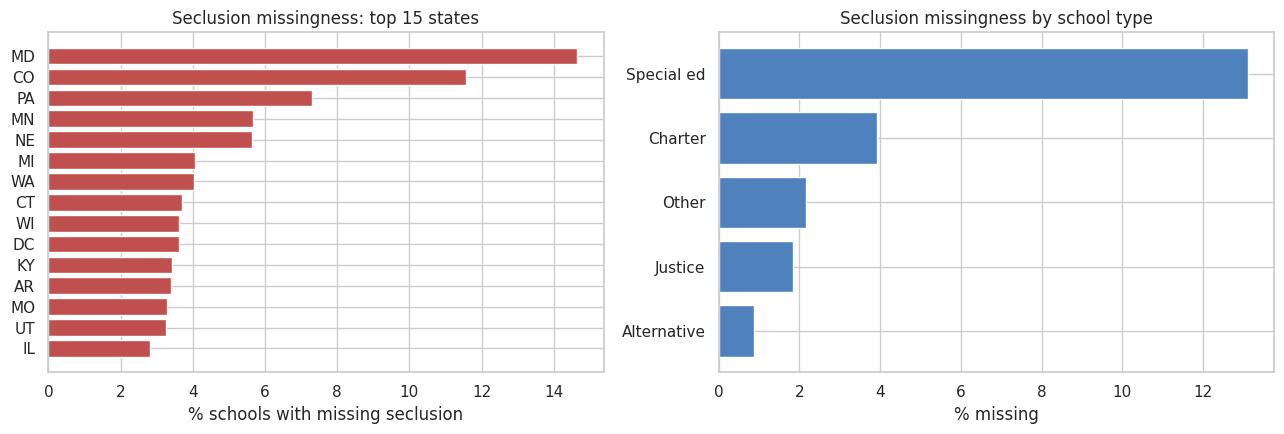

In [7]:
# How is seclusion missingness structured?
comp = ['seclusion_instances_idea','seclusion_instances_504','seclusion_instances_wodis']
n_comp_missing = full[comp].isna().sum(axis=1)
print('Number of missing seclusion components per school:'); print(n_comp_missing.value_counts().sort_index().to_string())
part = full[full.seclusion_instances.isna() & (full[comp].fillna(0).sum(axis=1) > 0)]
print(f'\nSchools with total missing but >=1 observed component > 0 (lower bound is known): {len(part)}')
print(f'Schools with total missing, 1-2 components missing, all observed components == 0: {int(((n_comp_missing.between(1,2)) & (full[comp].fillna(0).sum(axis=1)==0)).sum())}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
st = full.groupby('lea_state').flag_missing_seclusion.agg(['mean','sum']).sort_values('mean', ascending=False).head(15)
ax[0].barh(st.index[::-1], st['mean'][::-1]*100, color='#c0504d'); ax[0].set_xlabel('% schools with missing seclusion'); ax[0].set_title('Seclusion missingness: top 15 states')
tmp = full.assign(type=np.select([full.sch_status_sped.eq('Yes'), full.jj.eq('Yes'), full.sch_status_alt.eq('Yes'), full.sch_status_charter.eq('Yes')], ['Special ed','Justice','Alternative','Charter'], 'Other'))
t = tmp.groupby('type').flag_missing_seclusion.mean().sort_values()*100
ax[1].barh(t.index, t.values, color='#4f81bd'); ax[1].set_xlabel('% missing'); ax[1].set_title('Seclusion missingness by school type'); plt.tight_layout()

In [8]:
# Does dropping missing rows bias the analysis file? (full-file profile of missing vs non-missing)
prof = full.assign(any_flag=full.flag_missing_seclusion).groupby('any_flag').agg(
    n=('combokey','size'), median_enr=('enrollment_total','median'), mean_pct_idea=('pct_idea','mean'),
    pct_sped=('sch_status_sped', lambda s:(s=='Yes').mean()*100), pct_charter=('sch_status_charter', lambda s:(s=='Yes').mean()*100),
    pct_alt=('sch_status_alt', lambda s:(s=='Yes').mean()*100), pct_jj=('jj', lambda s:(s=='Yes').mean()*100))
prof

,n,median_enr,mean_pct_idea,pct_sped,pct_charter,pct_alt,pct_jj
any_flag,,,,,,,
False,93966,449.000,14.527,1.961,6.977,3.478,0.634
True,2394,161.000,30.624,11.612,11.111,1.086,0.501


In [9]:
# 2015-16-specific: what drives the IDEA-enrollment gaps, and is that missingness informative?
r = raw.loc[ana.index]
sup_m, sup_f = r.SCH_ENR_IDEA_M_code.eq(-2), r.SCH_ENR_IDEA_F_code.eq(-2)
print('IDEA enrollment suppressed (-2): male', int(sup_m.sum()), '| female', int(sup_f.sum()), '(analysis-ready rows)')
print('Rows where only ONE sex is suppressed (the other is known, but idea_n/pct_idea is set NA):', int((sup_m ^ sup_f).sum()))
miss_idea = ana.enr_idea.isna()
t = pd.DataFrame({'schools': [(~miss_idea).sum(), miss_idea.sum()], 'median_enrollment': [ana.loc[~miss_idea,'enrollment_total'].median(), ana.loc[miss_idea,'enrollment_total'].median()],
                  'pct_any_secl': [(ana.loc[~miss_idea,'seclusion_instances']>0).mean()*100, (ana.loc[miss_idea,'seclusion_instances']>0).mean()*100],
                  'pct_sped': [(ana.loc[~miss_idea,'sch_status_sped']=='Yes').mean()*100, (ana.loc[miss_idea,'sch_status_sped']=='Yes').mean()*100]}, index=['IDEA count known','IDEA count suppressed (NA)'])
print(t.round(2).to_string())
print('\nLaw-enforcement FTE (fte_leo): missing', f"{full.fte_leo.isna().mean():.1%}", '| reserved codes:', raw.SCH_FTESECURITY_LEO_code.value_counts().to_dict())
print('Top states for missing fte_leo:', full[full.fte_leo.isna()].lea_state.value_counts().head(6).to_dict())

IDEA enrollment suppressed (-2): male 5513 | female 8990 (analysis-ready rows)
Rows where only ONE sex is suppressed (the other is known, but idea_n/pct_idea is set NA): 4527
                            schools  median_enrollment  pct_any_secl  pct_sped
IDEA count known              84451            481.000         5.840     1.900
IDEA count suppressed (NA)     9515             65.000         2.450     2.500

Law-enforcement FTE (fte_leo): missing 73.6% | reserved codes: {-9.0: 69297, -5.0: 1640}
Top states for missing fte_leo: {'CA': 8339, 'TX': 5877, 'NY': 4343, 'FL': 3947, 'IL': 3388, 'MI': 3102}

## 3. Distribution of seclusion instances and rates (checklist 3)
`seclusion_rate` = instances per 100 enrolled students (instances are **events**, not students, so it can exceed 100).

In [10]:
df = ana.copy()
df['any_secl'] = (df.seclusion_instances > 0).astype(int)
x = df.seclusion_instances; r = df.seclusion_rate
print(f'Schools in analysis file: {len(df):,}')
print(f'Zero seclusion: {(x==0).mean():.2%} | any seclusion: {(x>0).mean():.2%} ({(x>0).sum():,} schools)')
print(f'Total instances: {x.sum():,.0f}; mean {x.mean():.3f}; skew {x.skew():.1f}; kurtosis {x.kurt():.0f}')
print('\nInstance quantiles (all schools):', x.quantile([.5,.9,.95,.975,.99,.999]).round(1).to_dict())
pos = df[df.any_secl==1]
print('\nAmong schools with >=1 instance:'); print(pos.seclusion_instances.describe(percentiles=[.25,.5,.75,.9,.95,.99]).round(2).to_string())
print('\nRate (per 100 students) among positives:'); print(pos.seclusion_rate.describe(percentiles=[.25,.5,.75,.9,.95,.99]).round(2).to_string())
srt = x.sort_values(ascending=False).cumsum()/x.sum()
for k in (10, 50, 100, 500, 1000): print(f'Top {k:>4} schools hold {srt.iloc[k-1]:.1%} of all instances')
print(f'Schools with rate > 100 per 100 students: {(r>100).sum()}  | rate > 25: {(r>25).sum()}')

Schools in analysis file: 93,966
Zero seclusion: 94.50% | any seclusion: 5.50% (5,165 schools)
Total instances: 130,301; mean 1.387; skew 63.0; kurtosis 5918

Instance quantiles (all schools): {0.5: 0.0, 0.9: 0.0, 0.95: 1.0, 0.975: 5.9, 0.99: 25.0, 0.999: 219.1}

Among schools with >=1 instance:
count   5,165.000
mean       25.230
std        99.040
min         1.000
25%         2.000
50%         4.000
75%        16.000
90%        50.000
95%        96.000
99%       370.080
max     3,088.000

Rate (per 100 students) among positives:
count   5,165.000
mean       16.010
std        96.090
min         0.020
25%         0.340
50%         1.150
75%         4.740
90%        17.720
95%        41.880
99%       345.170
max     3,057.430
Top   10 schools hold 12.7% of all instances
Top   50 schools hold 29.4% of all instances
Top  100 schools hold 39.8% of all instances
Top  500 schools hold 69.6% of all instances
Top 1000 schools hold 82.9% of all instances
Schools with rate > 100 per 100 students

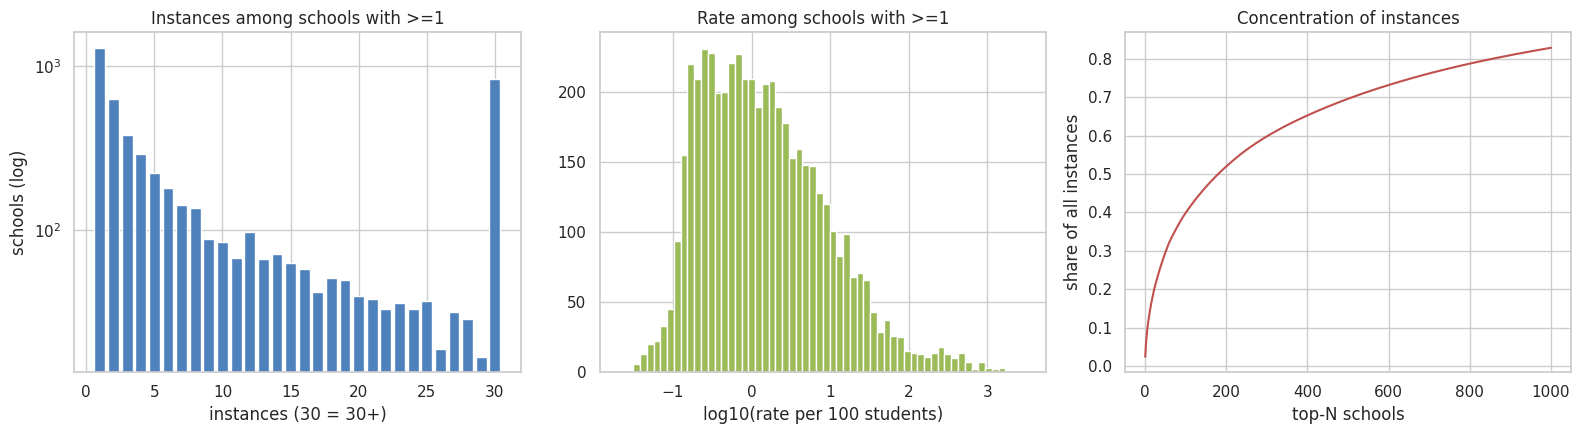

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
vc = pos.seclusion_instances.clip(upper=30).value_counts().sort_index()
ax[0].bar(vc.index.astype(int), vc.values, color='#4f81bd'); ax[0].set_yscale('log'); ax[0].set_xlabel('instances (30 = 30+)'); ax[0].set_ylabel('schools (log)'); ax[0].set_title('Instances among schools with >=1')
ax[1].hist(np.log10(pos.seclusion_rate), bins=60, color='#9bbb59'); ax[1].set_xlabel('log10(rate per 100 students)'); ax[1].set_title('Rate among schools with >=1')
ax[2].plot(np.arange(1, 1001), srt.values[:1000], color='#c0504d'); ax[2].set_xlabel('top-N schools'); ax[2].set_ylabel('share of all instances'); ax[2].set_title('Concentration of instances'); plt.tight_layout()

In [12]:
cols = ['sch_name','lea_name','lea_state','enrollment_total','seclusion_instances','seclusion_rate','sch_status_sped','sch_status_alt','jj']
print('Top 12 by instances'); display_top = df.nlargest(12, 'seclusion_instances')[cols]; print(display_top.to_string(index=False))
print('\nTop 12 by rate'); print(df.nlargest(12, 'seclusion_rate')[cols].to_string(index=False))

Top 12 by instances
                        sch_name                                    lea_name lea_state  enrollment_total  seclusion_instances  seclusion_rate sch_status_sped sch_status_alt  jj
Eastman Youth Development Campus              Department of Juvenile Justice        GA           101.000            3,088.000       3,057.426              No             No Yes
                       Davis Sch                                York City SD        PA           550.000            2,466.000         448.364              No             No  No
       Smouse Opportunity School Des Moines Independent Comm School District        IA           109.000            2,307.000       2,116.514              No             No  No
           Centralia High School                   Centralia School District        WA         1,060.000            1,615.000         152.358              No             No  No
        Community Youth Services                  Richmond Community Schools        IN         

## 4. Share reporting any seclusion and a threshold for "elevated" (checklist 4)

In [13]:
tiers = pd.DataFrame({'schools': [(x>=k).sum() for k in (1,2,3,5,10,20,50)], 'share_of_schools': [(x>=k).mean() for k in (1,2,3,5,10,20,50)],
                     'share_of_instances': [x[x>=k].sum()/x.sum() for k in (1,2,3,5,10,20,50)]}, index=[f'>= {k} instances' for k in (1,2,3,5,10,20,50)])
print(tiers.to_string())
# rate-based alternatives restricted to enrollment >= 30 (see section 9)
big = df[df.enrollment_total >= 30]
print('\nRate thresholds (enrollment >= 30): p90/p95/p99 among positives =', big[big.any_secl==1].seclusion_rate.quantile([.9,.95,.99]).round(2).to_dict())
print('Schools with rate >= 1 per 100 :', (big.seclusion_rate>=1).sum(), f'({(big.seclusion_rate>=1).mean():.2%})')
print('Schools with rate >= 5 per 100 :', (big.seclusion_rate>=5).sum(), f'({(big.seclusion_rate>=5).mean():.2%})')
print('Schools with >=5 instances AND rate >= 1 : ', ((big.seclusion_instances>=5)&(big.seclusion_rate>=1)).sum(), f'({((big.seclusion_instances>=5)&(big.seclusion_rate>=1)).mean():.2%})')

                 schools  share_of_schools  share_of_instances
>= 1 instances      5165             0.055               1.000
>= 2 instances      3878             0.041               0.990
>= 3 instances      3247             0.035               0.980
>= 5 instances      2574             0.027               0.963
>= 10 instances     1801             0.019               0.924
>= 20 instances     1147             0.012               0.854
>= 50 instances      520             0.006               0.704

Rate thresholds (enrollment >= 30): p90/p95/p99 among positives = {0.9: 15.07, 0.95: 31.13, 0.99: 251.71}
Schools with rate >= 1 per 100 : 2612 (2.88%)
Schools with rate >= 5 per 100 : 1147 (1.26%)
Schools with >=5 instances AND rate >= 1 :  2304 (2.54%)

In [14]:
# Is 'any' a one-off or a pattern? How does the share of schools with 1,2,3+ instances look within the positive group?
print((pos.seclusion_instances.clip(upper=10)).value_counts(normalize=True).sort_index().round(3).to_string())
# Which component drives it?
comp_tot = ana[['seclusion_instances_idea','seclusion_instances_504','seclusion_instances_wodis']].sum()
print('\nInstance totals by student group:'); print((comp_tot/comp_tot.sum()).round(4).to_string())
print('\nSchools with any instance, by group:', {c.replace('seclusion_instances_',''): int((ana[c]>0).sum()) for c in comp_tot.index})

seclusion_instances
1.000    0.249
2.000    0.122
3.000    0.074
4.000    0.056
5.000    0.043
6.000    0.035
7.000    0.028
8.000    0.027
9.000    0.017
10.000   0.349

Instance totals by student group:
seclusion_instances_idea    0.799
seclusion_instances_504     0.009
seclusion_instances_wodis   0.192

Schools with any instance, by group: {'idea': 4487, '504': 271, 'wodis': 1876}

## 5. School types and grade levels (checklist 5)

In [15]:
df['type_sped']=df.sch_status_sped.eq('Yes'); df['type_alt']=df.sch_status_alt.eq('Yes'); df['type_charter']=df.sch_status_charter.eq('Yes')
df['type_magnet']=df.sch_status_magnet.eq('Yes'); df['type_jj']=df.jj.eq('Yes')
df['type_virtual_name'] = df.sch_name.str.contains(r'virtual|online|cyber|e-?learning|distance', case=False, na=False)   # PROXY: no virtual indicator exists in 2015-16
df['regular'] = ~(df.type_sped | df.type_alt | df.type_jj)
df['enr_ge30'] = df.enrollment_total >= 30

def summ(d, by):
    g = d.groupby(by)
    out = pd.DataFrame({'schools': g.size(), 'pct_any_secl': g.any_secl.mean()*100,
        'mean_instances': g.seclusion_instances.mean(),
        'median_rate_if_any': g.apply(lambda s: s.loc[s.any_secl==1,'seclusion_rate'].median()),
        'share_of_all_instances_%': g.seclusion_instances.sum()/d.seclusion_instances.sum()*100})
    return out

rows = []
for col, lab in [('type_sped','Special education'),('type_alt','Alternative'),('type_charter','Charter'),('type_magnet','Magnet'),('type_jj','Justice facility'),('type_virtual_name','Virtual (name proxy)')]:
    t_ = summ(df, col); t_.index = t_.index.map({True: 'Yes', False: 'No'})
    rows += [t_.loc[['Yes']].rename(index={'Yes': lab}), t_.loc[['No']].rename(index={'No': lab + ' = No'})]
type_tbl = pd.concat(rows); type_tbl

,schools,pct_any_secl,mean_instances,median_rate_if_any,share_of_all_instances_%
Special education,1843,15.247,15.448,46.000,21.849
Special education = No,92123,5.302,1.105,1.024,78.151
Alternative,3268,2.509,1.462,11.997,3.667
Alternative = No,90698,5.604,1.384,1.124,96.333
Charter,6556,2.700,0.407,1.460,2.049
Charter = No,87410,5.706,1.460,1.144,97.951
Magnet,3608,3.797,0.475,0.366,1.314
Magnet = No,90358,5.565,1.423,1.189,98.686
Justice facility,596,6.711,6.809,26.453,3.114
Justice facility = No,93370,5.489,1.352,1.127,96.886


,schools,pct_any_secl,mean_instances,median_rate_if_any,share_of_all_instances_%
grade_band,,,,,
elementary,35612,7.380,1.525,1.333,41.688
high,16692,2.468,0.473,0.477,6.053
middle,12841,4.283,0.593,0.506,5.843
other,215,11.163,7.460,16.667,1.231
span,28606,5.422,2.058,1.647,45.185


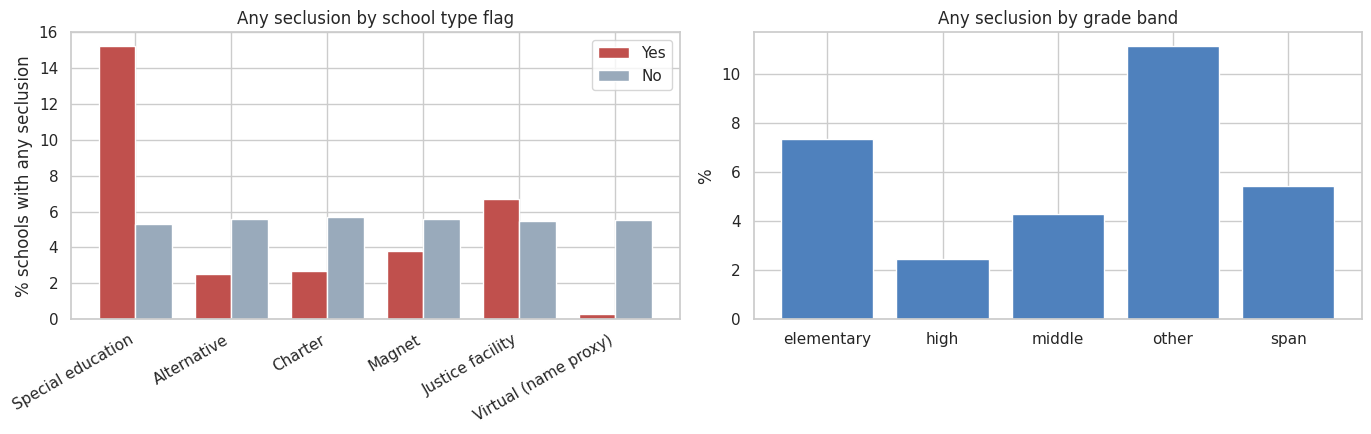

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
labs = ['Special education','Alternative','Charter','Magnet','Justice facility','Virtual (name proxy)']; cols = ['type_sped','type_alt','type_charter','type_magnet','type_jj','type_virtual_name']
yes = [df.loc[df[c],'any_secl'].mean()*100 for c in cols]; no = [df.loc[~df[c],'any_secl'].mean()*100 for c in cols]
w=.38; i=np.arange(len(cols)); ax[0].bar(i-w/2, yes, w, label='Yes', color='#c0504d'); ax[0].bar(i+w/2, no, w, label='No', color='#9ab'); ax[0].set_xticks(i); ax[0].set_xticklabels(labs, rotation=30, ha='right'); ax[0].set_ylabel('% schools with any seclusion'); ax[0].legend(); ax[0].set_title('Any seclusion by school type flag')
gb = summ(df, 'grade_band'); ax[1].bar(gb.index, gb.pct_any_secl, color='#4f81bd'); ax[1].set_title('Any seclusion by grade band'); ax[1].set_ylabel('%')
plt.tight_layout(); gb

In [17]:
# Grade band within regular schools only (removes the special-ed / alternative / justice effect) and type x grade
print('Regular schools (not sped / alt / justice) by grade band'); print(summ(df[df.regular], 'grade_band').round(2).to_string())
print(f'\nShare of the {len(pos):,} schools with any seclusion that are...')
pos = df[df.any_secl==1]
print({k: f'{pos[k].mean():.1%} (vs {df[k].mean():.1%} of all schools)' for k in ['type_sped','type_alt','type_charter','type_magnet','type_jj','type_virtual_name']})
print('\nRegular school share of positives:', f'{pos.regular.mean():.1%}')

Regular schools (not sped / alt / justice) by grade band
            schools  pct_any_secl  mean_instances  median_rate_if_any  share_of_all_instances_%
grade_band                                                                                     
elementary    35312         7.310           1.450               1.290                    53.070
high          14765         2.610           0.510               0.410                     7.760
middle        12664         4.310           0.600               0.500                     7.820
other            77         0.000           0.000                 NaN                     0.000
span          25768         4.960           1.180               1.040                    31.350

Share of the 5,165 schools with any seclusion that are...
{'type_sped': '5.4% (vs 2.0% of all schools)', 'type_alt': '1.6% (vs 3.5% of all schools)', 'type_charter': '3.4% (vs 7.0% of all schools)', 'type_magnet': '2.7% (vs 3.8% of all schools)', 'type_jj': '0.8% (vs 0.

## 6. States and districts (checklist 6)

In [18]:
stt = df.groupby('lea_state').agg(schools=('combokey','size'), pct_any=('any_secl', lambda s: s.mean()*100), instances=('seclusion_instances','sum'), enroll=('enrollment_total','sum'))
stt['instances_per_1000_students'] = stt.instances/stt.enroll*1000
stt['pct_missing_in_full_file'] = full.groupby('lea_state').flag_missing_seclusion.mean()*100
stt = stt.sort_values('pct_any', ascending=False)
print('Top 10 / bottom 12 states by % schools with any seclusion'); print(pd.concat([stt.head(10), stt.tail(12)]).round(2).to_string())
print('\nStates with 0 schools reporting any seclusion:', stt.index[stt.pct_any==0].tolist())
print('Median state % any:', round(stt.pct_any.median(),2), '| IQR', stt.pct_any.quantile([.25,.75]).round(2).tolist())

Top 10 / bottom 12 states by % schools with any seclusion
           schools  pct_any  instances        enroll  instances_per_1000_students  pct_missing_in_full_file
lea_state                                                                                                  
WI            2151   28.130 10,684.000   852,996.000                       12.530                     3.630
ME             584   25.000  2,463.000   178,212.000                       13.820                     0.850
IA            1336   25.000 15,482.000   500,394.000                       30.940                     2.120
CT            1192   22.820  5,940.000   532,821.000                       11.150                     3.720
VT             305   19.020  1,067.000    83,341.000                       12.800                     0.330
KS            1338   16.220  3,910.000   489,228.000                        7.990                     1.330
WA            2212   15.280 11,492.000 1,089,456.000                       10.

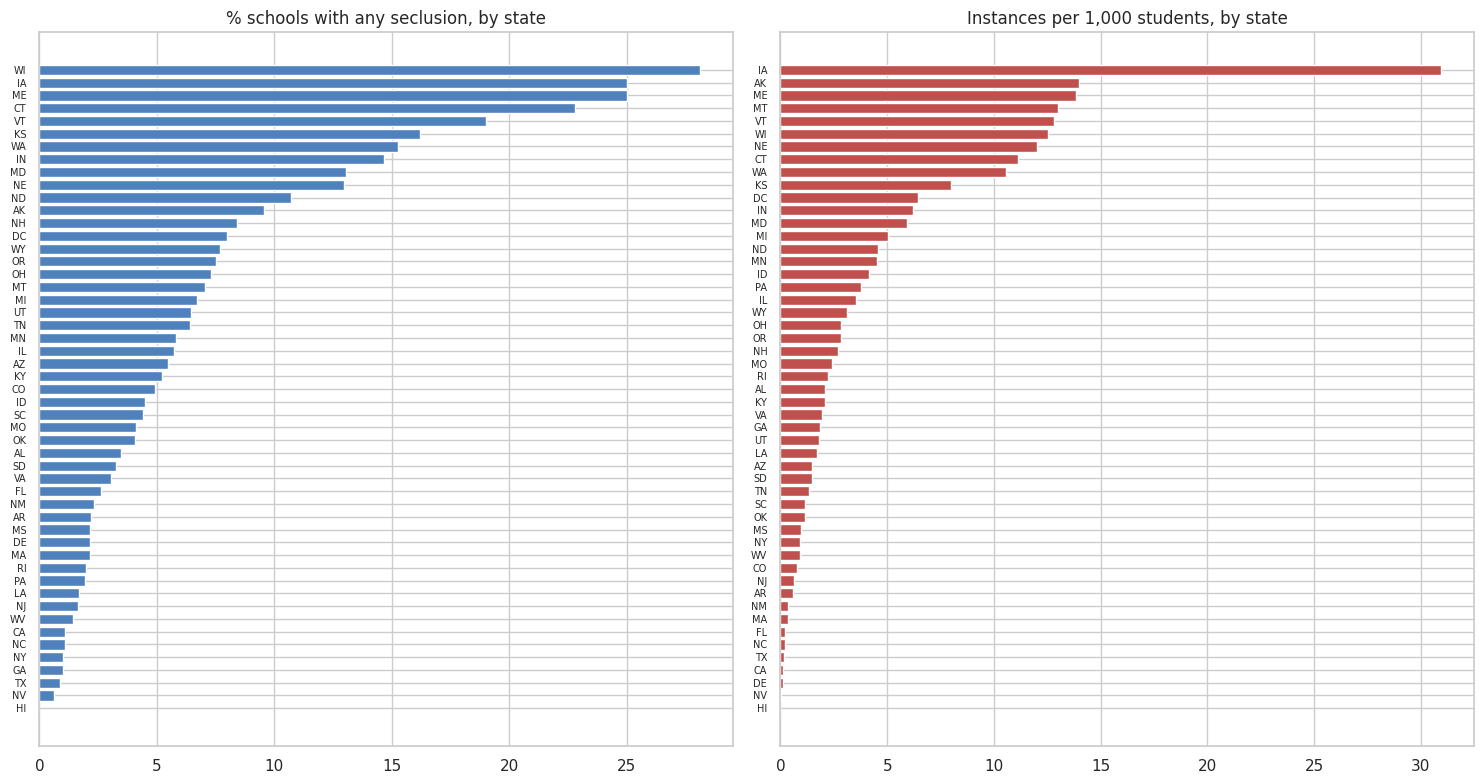

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(15, 8))
s = stt.sort_values('pct_any'); ax[0].barh(s.index, s.pct_any, color='#4f81bd'); ax[0].set_title('% schools with any seclusion, by state'); ax[0].tick_params(axis='y', labelsize=7)
s = stt.sort_values('instances_per_1000_students'); ax[1].barh(s.index, s.instances_per_1000_students, color='#c0504d'); ax[1].set_title('Instances per 1,000 students, by state'); ax[1].tick_params(axis='y', labelsize=7); plt.tight_layout()

Districts: 17,307; with >=1 school reporting any seclusion: 2,111 (12.2%)
Top  10 districts = 20.5% of instances
Top  50 districts = 43.7% of instances
Top 100 districts = 57.5% of instances
Top 500 districts = 89.1% of instances
Districts that account for 50% of instances: 70; for 80%: 291
                                            lea_name state  schools  schools_any  instances     enroll  share_instances_%  cum_share_%
leaid                                                                                                                                 
4226820                                 York City SD    PA        8            8  4,852.000  5,143.000              3.700        3.700
1908970  Des Moines Independent Comm School District    IA       58           26  4,497.000 32,039.000              3.500        7.200
5301140                    Centralia School District    WA        8            8  3,702.000  3,608.000              2.800       10.000
1300026               Department 

(0.0, 10.0)

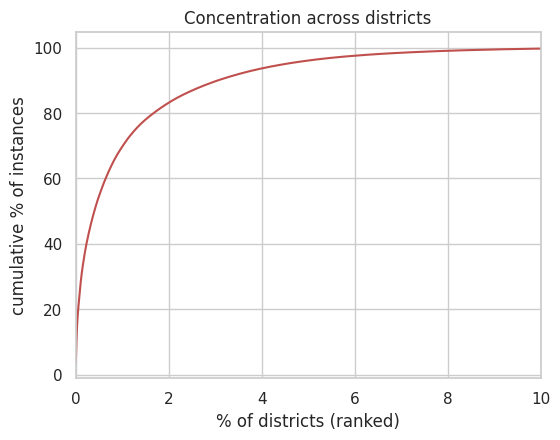

In [20]:
dist = df.groupby(['leaid']).agg(lea_name=('lea_name','first'), state=('lea_state','first'), schools=('combokey','size'), schools_any=('any_secl','sum'),
                                  instances=('seclusion_instances','sum'), enroll=('enrollment_total','sum')).sort_values('instances', ascending=False)
dist['share_instances_%'] = dist.instances/dist.instances.sum()*100; dist['cum_share_%'] = dist['share_instances_%'].cumsum()
print(f'Districts: {len(dist):,}; with >=1 school reporting any seclusion: {(dist.schools_any>0).sum():,} ({(dist.schools_any>0).mean():.1%})')
for k in (10, 50, 100, 500): print(f'Top {k:>3} districts = {dist.instances.iloc[:k].sum()/dist.instances.sum():.1%} of instances')
print(f'Districts that account for 50% of instances: {(dist["cum_share_%"]<50).sum()+1}; for 80%: {(dist["cum_share_%"]<80).sum()+1}')
print(dist.head(15).round(1).to_string())
fig, ax = plt.subplots(figsize=(6,4.5)); d2 = dist[dist.instances>0]; ax.plot(np.arange(1,len(d2)+1)/len(dist)*100, d2['cum_share_%'].values, color='#c0504d'); ax.set_xlabel('% of districts (ranked)'); ax.set_ylabel('cumulative % of instances'); ax.set_title('Concentration across districts'); ax.set_xlim(0,10)

In [21]:
# Within-state vs between-state: how much of 'any seclusion' is explained by state alone, and by district?
from sklearn.metrics import roc_auc_score
st_mean = df.groupby('lea_state').any_secl.transform('mean'); print('AUC of state-mean alone    :', round(roc_auc_score(df.any_secl, st_mean),3))
lea_mean = df.groupby('leaid').any_secl.transform('mean'); print('AUC of district-mean (in-sample, optimistic, leaky):', round(roc_auc_score(df.any_secl, lea_mean),3))
print('Positives sitting in districts where >=50% of schools are positive:', f"{pos.leaid.map(df.groupby('leaid').any_secl.mean()).ge(.5).mean():.1%}")
print('Single-school districts among positives:', f"{(pos.leaid.map(df.groupby('leaid').size())==1).mean():.1%}")

AUC of state-mean alone    : 0.785
AUC of district-mean (in-sample, optimistic, leaky): 0.969
Positives sitting in districts where >=50% of schools are positive: 44.5%
Single-school districts among positives: 5.7%

## 7. Staffing and seclusion (checklist 7)
Per-100 ratios are rebuilt from the FTE counts, with rows flagged `flag_fte_outlier` excluded and ratios capped at the 99.5th percentile, because several FTE values are impossible (e.g. 19,048.6 psychologists at one school — see Data Issues).

In [22]:
st = df[~df.flag_fte_outlier & df.enrollment_total.ge(30)].copy()
for c in ['counselors','psych','social','nurses','leo','guards','teachers']:
    st[f'{c}_p100'] = st[f'fte_{c}']/st.enrollment_total*100
    st[f'{c}_p100'] = st[f'{c}_p100'].clip(upper=st[f'{c}_p100'].quantile(.995))
staff = ['counselors','psych','social','nurses','leo','guards']
staff_reg = [c for c in staff if c != 'leo']   # fte_leo is 73% structurally missing in 2015-16 -> excluded from models
print('Schools with usable fte_leo among enr>=30:', int(st.fte_leo.notna().sum()), 'of', len(st))
out = []
for c in staff:
    for lab, d in [('All (enr>=30)', st), ('Regular schools', st[st.regular])]:
        d = d.dropna(subset=[f'fte_{c}'])
        has = d[f'fte_{c}']>0
        pos_p = d.loc[has, f'{c}_p100']; terc = pd.qcut(pos_p, 3, labels=['low','mid','high'], duplicates='drop')
        r = {'staff': c, 'sample': lab, 'share_with_any_FTE_%': has.mean()*100, 'any_secl_%_none': d.loc[~has,'any_secl'].mean()*100}
        for t in ['low','mid','high']: r[f'any_secl_%_{t}'] = d.loc[pos_p.index[terc==t],'any_secl'].mean()*100
        out.append(r)
staff_tbl = pd.DataFrame(out).set_index(['staff','sample']); staff_tbl.round(2)

Schools with usable fte_leo among enr>=30: 24801 of 90637

share_with_any_FTE_%  any_secl_%_none  any_secl_%_low  any_secl_%_mid  any_secl_%_high
staff      sample                                                                                                 
counselors All (enr>=30)                  75.410            5.850           6.190           5.970            4.210
           Regular schools                76.460            5.510           6.230           6.010            4.180
psych      All (enr>=30)                  47.370            4.020           6.250           8.370            7.150
           Regular schools                47.780            3.940           6.270           8.430            6.800
social     All (enr>=30)                  28.980            4.770           7.410           7.310            7.690
           Regular schools                28.870            4.780           7.570           7.320            6.730
nurses     All (enr>=30)                  67.420            3.800           7.500           5.900            5.820
           Regular schools                68.530            3.680           7.570           5.890            5.460
leo        All (enr>=30)                  88.750            5.990           8.320           5.310            4.170
           Regular schools                88.860            6.020           8.420           5.350            4.000
guards     All (enr>=30)                  13.630            5.870           5.970           3.550            3.350
           Regular schools                13.410            5.800           6.030           3.570            2.910

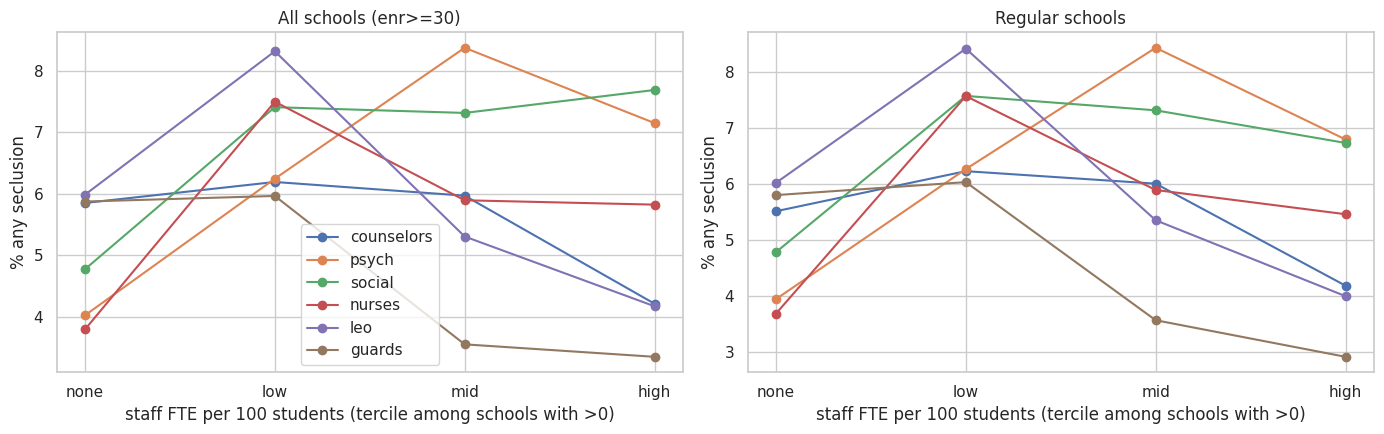

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (lab, d) in zip(axes, [('All schools (enr>=30)', st), ('Regular schools', st[st.regular])]):
    for c in staff:
        dd = d.dropna(subset=[f'fte_{c}']); has = dd[f'fte_{c}']>0; pp = dd.loc[has, f'{c}_p100']; t = pd.qcut(pp, 3, labels=['low','mid','high'], duplicates='drop')
        vals = [dd.loc[~has,'any_secl'].mean()*100] + [dd.loc[pp.index[t==k],'any_secl'].mean()*100 for k in ['low','mid','high']]
        ax.plot(['none','low','mid','high'], vals, marker='o', label=c)
    ax.set_title(lab); ax.set_ylabel('% any seclusion'); ax.set_xlabel('staff FTE per 100 students (tercile among schools with >0)')
axes[0].legend(); plt.tight_layout()

In [24]:
# Staffing relationship after controlling for size, school type, grade band and population (logistic regression, standardised)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
X = st[st.regular].dropna(subset=['pct_idea','pct_el','pct_504']+[f'{c}_p100' for c in staff_reg]).copy()
feat = ['log_enr','pct_idea','pct_504','pct_el']+[f'{c}_p100' for c in staff_reg]
X['log_enr'] = np.log(X.enrollment_total)
Xd = pd.concat([X[feat], pd.get_dummies(X.grade_band, drop_first=True, dtype=float)], axis=1)
m = LogisticRegression(max_iter=2000, C=1.0).fit(StandardScaler().fit_transform(Xd), X.any_secl)
coef = pd.Series(m.coef_[0], index=Xd.columns).sort_values(); print('Standardised log-odds coefficients (regular schools, enr>=30):'); coef.round(3)

Standardised log-odds coefficients (regular schools, enr>=30):

,0
high,-0.396
pct_el,-0.236
middle,-0.199
span,-0.182
pct_504,-0.150
guards_p100,-0.123
nurses_p100,-0.039
other,-0.038
counselors_p100,-0.003
psych_p100,0.077


## 8. Student population and seclusion (checklist 8)

pct_idea
                size  pct_any
pct_idea_bin                 
(-0.1, 5.0]     2404    2.040
(5.0, 10.0]    21647    4.540
(10.0, 15.0]   32218    6.060
(15.0, 20.0]   16931    6.680
(20.0, 30.0]    7212    6.460
(30.0, 50.0]     916    5.350
(50.0, 100.1]    163    9.200 

pct_504
                size  pct_any
pct_504_bin                  
(-0.1, 0.5]    22787    5.620
(0.5, 2.0]     28353    6.630
(2.0, 5.0]     21027    5.500
(5.0, 10.0]     7831    3.750
(10.0, 100.1]   1493    2.410 

pct_el
                size  pct_any
pct_el_bin                   
(-0.1, 1.0]    24292    5.060
(1.0, 5.0]     23290    6.570
(5.0, 15.0]    17127    6.510
(15.0, 40.0]   11915    5.430
(40.0, 100.1]   4867    2.570 

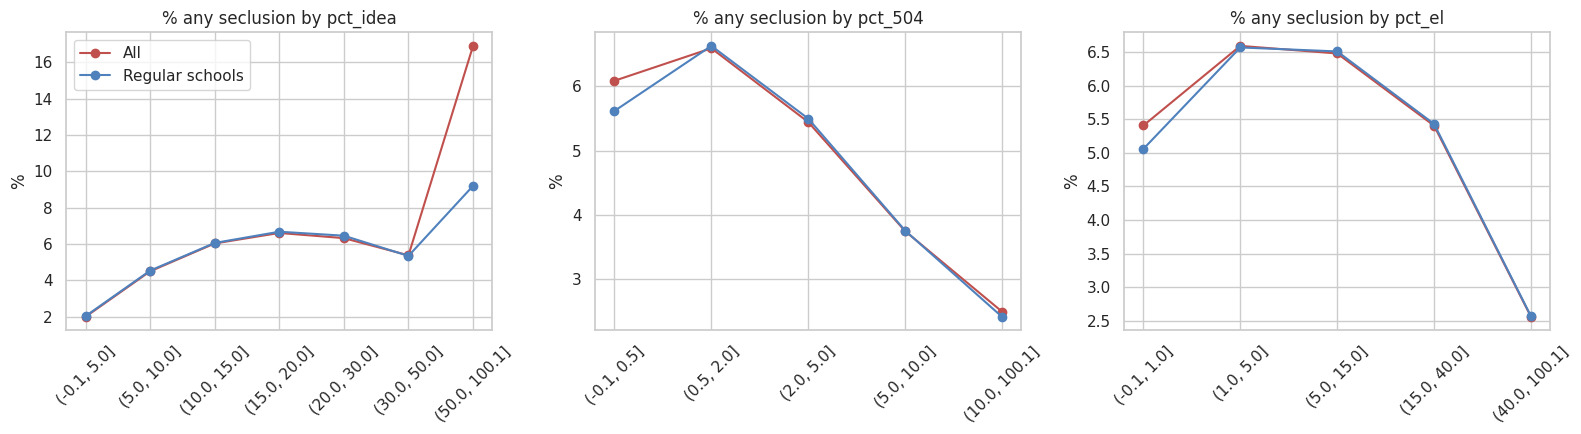

In [25]:
pp = df[df.enr_ge30 & df.pct_idea.notna() & df.pct_el.notna() & df.pct_504.notna()].copy()
bins = {'pct_idea':[-.1,5,10,15,20,30,50,100.1], 'pct_504':[-.1,.5,2,5,10,100.1], 'pct_el':[-.1,1,5,15,40,100.1]}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5)); res = {}
for ax, (c, b) in zip(axes, bins.items()):
    pp[c+'_bin'] = pd.cut(pp[c], b)
    for lab, d, col in [('All', pp, '#c0504d'), ('Regular schools', pp[pp.regular], '#4f81bd')]:
        g = d.groupby(c+'_bin', observed=True).any_secl.agg(['mean','size']); ax.plot(g.index.astype(str), g['mean']*100, marker='o', label=lab, color=col); res[(c, lab)] = g
    ax.set_title(f'% any seclusion by {c}'); ax.tick_params(axis='x', rotation=45); ax.set_ylabel('%')
axes[0].legend(); plt.tight_layout()
for k, v in res.items():
    if k[1]=='Regular schools': print(k[0]); print((v.assign(**{'pct_any': v['mean']*100}).drop(columns='mean')).round(2).to_string(), '\n')

In [26]:
sp = pp[['any_secl','pct_idea','pct_504','pct_el','seclusion_rate','enrollment_total']].copy(); sp['log_enr']=np.log(sp.enrollment_total)
print('Spearman with any_secl (all, enr>=30):'); print(sp.corr(method='spearman')['any_secl'].drop('any_secl').round(3).to_string())
r_ = pp[pp.regular]; print('\nSpearman with any_secl (regular schools):'); print(r_[['any_secl','pct_idea','pct_504','pct_el']].corr(method='spearman')['any_secl'].drop('any_secl').round(3).to_string())
print('\nRegular schools, any_secl by whether %IDEA is above regular-school median:', r_.groupby(r_.pct_idea>r_.pct_idea.median()).any_secl.mean().mul(100).round(2).to_dict())

Spearman with any_secl (all, enr>=30):
pct_idea            0.049
pct_504            -0.030
pct_el             -0.008
seclusion_rate      0.999
enrollment_total   -0.020
log_enr            -0.020

Spearman with any_secl (regular schools):
pct_idea    0.040
pct_504    -0.022
pct_el     -0.001

Regular schools, any_secl by whether %IDEA is above regular-school median: {False: 5.03, True: 6.37}

## 9. Small enrollments and rate distortion (checklist 9)
A single instance in a school of 10 students is a rate of 10 per 100. Rates for tiny schools are driven by the denominator.

                  schools  pct_any  median_rate_if_any  p95_rate_if_any  pct_rate_gt_100  pct_special_ed
enrollment_total                                                                                        
1-9                   969    2.890              40.970          491.250            1.140          13.210
10-29                2243    3.920              50.000          530.970            1.290          12.040
30-99                5851    4.360              17.390          543.330            1.010          10.990
100-249             13036    4.460               2.590           68.380            0.180           3.500
250-499             31425    6.720               1.360           20.460            0.020           0.720
500-999             31611    5.550               0.570           15.320            0.020           0.290
1000+                8831    3.950               0.190            3.130            0.010           0.310

Schools under 30 students: 3,212 (3.4%); they hold 2.2

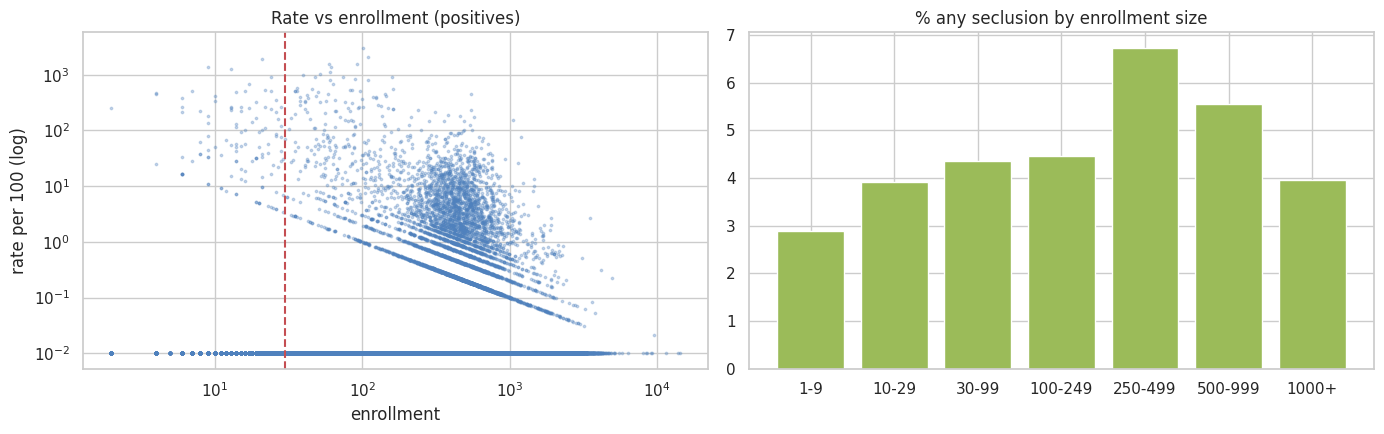

In [27]:
eb = pd.cut(df.enrollment_total, [0,9,29,99,249,499,999,1e6], labels=['1-9','10-29','30-99','100-249','250-499','500-999','1000+'])
g = df.groupby(eb, observed=True)
small = pd.DataFrame({'schools': g.size(), 'pct_any': g.any_secl.mean()*100,
    'median_rate_if_any': g.apply(lambda s: s.loc[s.any_secl==1,'seclusion_rate'].median()),
    'p95_rate_if_any': g.apply(lambda s: s.loc[s.any_secl==1,'seclusion_rate'].quantile(.95)),
    'pct_rate_gt_100': g.apply(lambda s: (s.seclusion_rate>100).mean()*100),
    'pct_special_ed': g.type_sped.mean()*100})
print(small.round(2).to_string())
print(f'\nSchools under 30 students: {(df.enrollment_total<30).sum():,} ({(df.enrollment_total<30).mean():.1%}); they hold {df.loc[df.enrollment_total<30,"seclusion_instances"].sum()/df.seclusion_instances.sum():.1%} of instances but {(df.loc[df.seclusion_rate>100].enrollment_total<30).mean():.0%} of rate>100 schools')
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].scatter(df.enrollment_total, df.seclusion_rate.clip(lower=.01), s=3, alpha=.3, color='#4f81bd'); ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('enrollment'); ax[0].set_ylabel('rate per 100 (log)'); ax[0].set_title('Rate vs enrollment (positives)'); ax[0].axvline(30, color='r', ls='--')
ax[1].bar(small.index.astype(str), small.pct_any, color='#9bbb59'); ax[1].set_title('% any seclusion by enrollment size'); plt.tight_layout()

In [28]:
# Candidate smoothing: empirical-Bayes-style shrinkage toward the overall rate, k = pseudo-students
m0 = df.seclusion_instances.sum()/df.enrollment_total.sum()*100
for k in (30, 100): df[f'rate_eb_k{k}'] = (df.seclusion_instances + k*m0/100)/(df.enrollment_total + k)*100
top = lambda col, n=100: set(df.nlargest(n, col).combokey)
print(f'Overall rate m0 = {m0:.2f} per 100')
for col in ['seclusion_rate','rate_eb_k30','rate_eb_k100']:
    t = df.nlargest(100, col); print(f'{col:>14}: median enrollment of top-100 = {t.enrollment_total.median():.0f}; share with enrollment<30 = {(t.enrollment_total<30).mean():.0%}; share sped = {t.type_sped.mean():.0%}')
print('\nOverlap of top-100 raw vs EB(k=30):', len(top('seclusion_rate') & top('rate_eb_k30')), '| min-enrollment-30 raw top-100 vs EB(k=30):', len(set(df[df.enr_ge30].nlargest(100,'seclusion_rate').combokey) & top('rate_eb_k30')))

Overall rate m0 = 0.26 per 100
seclusion_rate: median enrollment of top-100 = 50; share with enrollment<30 = 32%; share sped = 76%
   rate_eb_k30: median enrollment of top-100 = 76; share with enrollment<30 = 16%; share sped = 74%
  rate_eb_k100: median enrollment of top-100 = 90; share with enrollment<30 = 9%; share sped = 65%

Overlap of top-100 raw vs EB(k=30): 84 | min-enrollment-30 raw top-100 vs EB(k=30): 84

## 10. 2015-16 vs 2017-18 (checklist 10, adapted)
The checklist asks for 2017-18 vs 2021-22; 2021-22 was not supplied, so this section uses the two years available: 2015-16 vs 2017-18 for schools present in both (joined on rebuilt `combokey`). 2020-21 is not needed for this pair.

2015-16 analysis-ready: 93,966 | 2017-18 analysis-ready: 91,013 | in both: 86,019 (91.5% of 2015-16, 94.5% of 2017-18)
Prevalence of any seclusion (all schools):  2015-16 5.50% | 2017-18 6.56%
Prevalence among schools in both years:      2015-16 5.65% | 2017-18 6.74%

any_17           any in 2017-18  none in 2017-18
any_secl                                        
any in 2015-16             2292             2568
none in 2015-16            3509            77650

Persistence: P(any in 2017-18 | any in 2015-16) = 47.2% | P(any in 2017-18 | none in 2015-16) = 4.3%
Share of 2017-18 positives that were also positive in 2015-16: 39.5%
Spearman of instances across years: 0.405 | of rate per 100: 0.404

"Elevated" (>=5 instances and >=1 per 100), schools with enr>=30 in both years: 2015-16 2.59% | 2017-18 3.17% | persistence P(elev17 | elev15) = 47.2%
State-level prevalence correlation 2015-16 vs 2017-18: Pearson 0.974, Spearman 0.959

,p15,p17,change
lea_state,,,
MT,7.000,2.800,-4.200
ND,10.700,9.100,-1.600
SD,3.200,2.200,-1.100
MD,13.100,12.000,-1.000
WI,28.100,33.200,5.100
MI,6.700,13.000,6.300
KS,16.200,22.900,6.700
UT,6.500,13.200,6.700


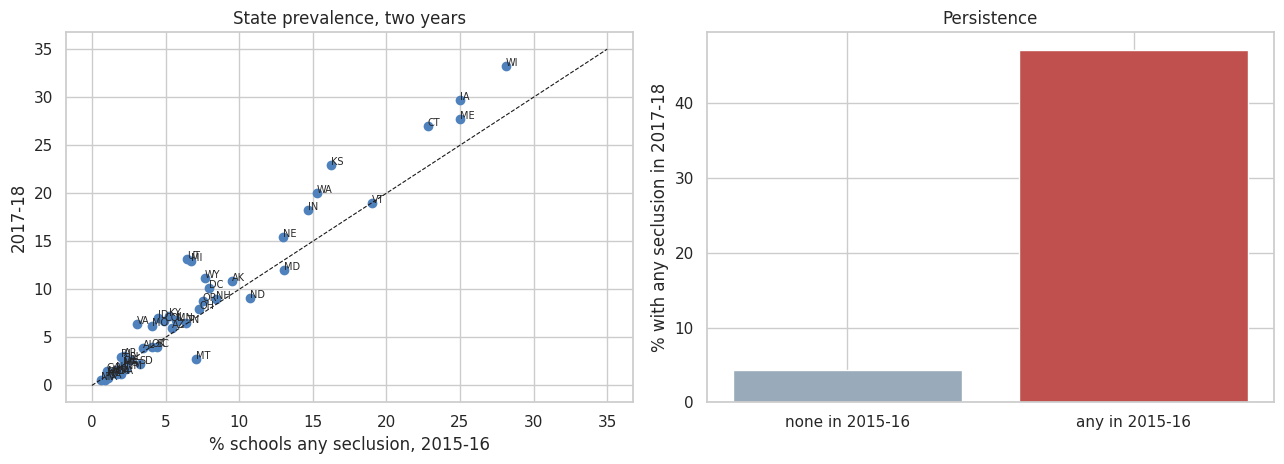

In [29]:
n17 = pd.read_csv(DATA_DIR/'schools_201718_analysis.csv', usecols=['combokey','seclusion_instances','enrollment_total','lea_state','seclusion_rate'], dtype={'combokey': str, 'lea_state': str})
j = df[['combokey','lea_state','seclusion_instances','enrollment_total','seclusion_rate','any_secl']].merge(n17, on='combokey', suffixes=('_15','_17'))
j['any_17'] = (j.seclusion_instances_17 > 0).astype(int)
print(f'2015-16 analysis-ready: {len(df):,} | 2017-18 analysis-ready: {len(n17):,} | in both: {len(j):,} ({len(j)/len(df):.1%} of 2015-16, {len(j)/len(n17):.1%} of 2017-18)')
print(f'Prevalence of any seclusion (all schools):  2015-16 {df.any_secl.mean():.2%} | 2017-18 {(n17.seclusion_instances>0).mean():.2%}')
print(f'Prevalence among schools in both years:      2015-16 {j.any_secl.mean():.2%} | 2017-18 {j.any_17.mean():.2%}')
tm = pd.crosstab(j.any_secl.map({0:'none in 2015-16',1:'any in 2015-16'}), j.any_17.map({0:'none in 2017-18',1:'any in 2017-18'})); print(); print(tm.to_string())
print(f'\nPersistence: P(any in 2017-18 | any in 2015-16) = {j.loc[j.any_secl==1,"any_17"].mean():.1%} | P(any in 2017-18 | none in 2015-16) = {j.loc[j.any_secl==0,"any_17"].mean():.1%}')
print(f'Share of 2017-18 positives that were also positive in 2015-16: {j.loc[j.any_17==1,"any_secl"].mean():.1%}')
print('Spearman of instances across years:', round(j[['seclusion_instances_15','seclusion_instances_17']].corr(method='spearman').iloc[0,1],3), '| of rate per 100:', round(j[['seclusion_rate_15','seclusion_rate_17']].corr(method='spearman').iloc[0,1],3))
big = j[(j.enrollment_total_15>=30)&(j.enrollment_total_17>=30)]
el15 = (big.seclusion_instances_15>=5)&(big.seclusion_rate_15>=1); el17 = (big.seclusion_instances_17>=5)&(big.seclusion_rate_17>=1)
print(f'\n"Elevated" (>=5 instances and >=1 per 100), schools with enr>=30 in both years: 2015-16 {el15.mean():.2%} | 2017-18 {el17.mean():.2%} | persistence P(elev17 | elev15) = {el17[el15].mean():.1%}')
s15 = df.groupby('lea_state').any_secl.mean()*100; s17 = n17.assign(a=n17.seclusion_instances>0).groupby('lea_state').a.mean()*100
sc = pd.concat([s15.rename('p15'), s17.rename('p17')], axis=1).dropna()
print(f'State-level prevalence correlation 2015-16 vs 2017-18: Pearson {sc.corr().iloc[0,1]:.3f}, Spearman {sc.corr(method="spearman").iloc[0,1]:.3f}')
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].scatter(sc.p15, sc.p17, color='#4f81bd'); [ax[0].annotate(k, (v.p15, v.p17), fontsize=7) for k, v in sc.iterrows()]
ax[0].plot([0, 35], [0, 35], 'k--', lw=.8); ax[0].set_xlabel('% schools any seclusion, 2015-16'); ax[0].set_ylabel('2017-18'); ax[0].set_title('State prevalence, two years')
pr = pd.Series({'none in 2015-16': j.loc[j.any_secl==0,'any_17'].mean()*100, 'any in 2015-16': j.loc[j.any_secl==1,'any_17'].mean()*100})
ax[1].bar(pr.index, pr.values, color=['#9ab', '#c0504d']); ax[1].set_ylabel('% with any seclusion in 2017-18'); ax[1].set_title('Persistence'); plt.tight_layout()
sc.assign(change=sc.p17-sc.p15).sort_values('change').round(1).iloc[[0,1,2,3,-4,-3,-2,-1]]

## 11. Equity patterns (checklist 11, descriptive only)
This file has **students secluded** (unique students) by sex and IDEA status, and instance counts by IDEA / 504 / no-disability. **Race is not in the cleaned file**; the 2015-16 raw CRDC has race columns, so they must be carried through cleaning to complete this item.

Schools with all counts valid: 84,450 of 93,966 (the rest have suppressed IDEA counts or missing seclusion)

All schools
                secluded_students  enrolled_students  secluded_per_100_students  share_of_secluded_%  share_of_enrolled_%  ratio_vs_no_IDEA_female
IDEA male              19,513.000      4,108,029.000                      0.475               54.594                8.452                   31.448
IDEA female             4,999.000      2,085,243.000                      0.240               13.986                4.290                   15.872
No IDEA male            7,975.000     20,862,892.000                      0.038               22.313               42.922                    2.531
No IDEA female          3,255.000     21,550,545.000                      0.015                9.107               44.337                    1.000

Regular schools only (not sped / alt / justice)
                secluded_students  enrolled_students  secluded_per_100_students  share_of_seclu

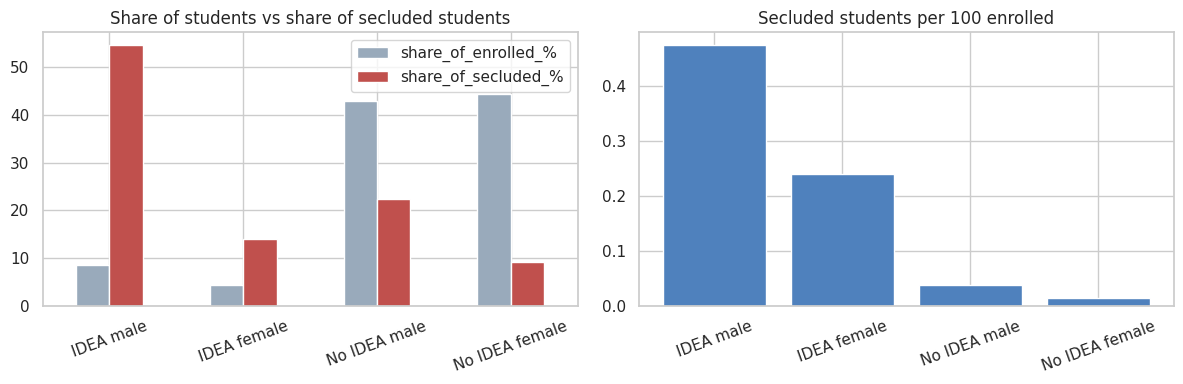

In [30]:
r = raw.loc[df.index]
eq = pd.DataFrame({'tot_m': r.TOT_ENR_M, 'tot_f': r.TOT_ENR_F, 'idea_m': r.SCH_ENR_IDEA_M, 'idea_f': r.SCH_ENR_IDEA_F,
                   'sec_idea_m': r.TOT_RS_IDEA_SECL_M, 'sec_idea_f': r.TOT_RS_IDEA_SECL_F, 'sec_non_m': r.TOT_RS_NONIDEA_SECL_M, 'sec_non_f': r.TOT_RS_NONIDEA_SECL_F,
                   'inst_idea': r.SCH_RSINSTANCES_SECL_IDEA, 'inst_wodis': r.SCH_RSINSTANCES_SECL_WODIS, 'inst_504': r.SCH_RSINSTANCES_SECL_504,
                   'regular': df.regular}).dropna(subset=['tot_m','tot_f','idea_m','idea_f','sec_idea_m','sec_idea_f','sec_non_m','sec_non_f'])
eq['non_m'] = (eq.tot_m - eq.idea_m).clip(lower=0); eq['non_f'] = (eq.tot_f - eq.idea_f).clip(lower=0)
def tbl(d):
    t = pd.DataFrame({'secluded_students': [d.sec_idea_m.sum(), d.sec_idea_f.sum(), d.sec_non_m.sum(), d.sec_non_f.sum()],
                      'enrolled_students': [d.idea_m.sum(), d.idea_f.sum(), d.non_m.sum(), d.non_f.sum()]}, index=['IDEA male','IDEA female','No IDEA male','No IDEA female'])
    t['secluded_per_100_students'] = t.secluded_students/t.enrolled_students*100
    t['share_of_secluded_%'] = t.secluded_students/t.secluded_students.sum()*100; t['share_of_enrolled_%'] = t.enrolled_students/t.enrolled_students.sum()*100
    t['ratio_vs_no_IDEA_female'] = t.secluded_per_100_students/t.loc['No IDEA female','secluded_per_100_students']; return t
print(f'Schools with all counts valid: {len(eq):,} of {len(df):,} (the rest have suppressed IDEA counts or missing seclusion)')
print('\nAll schools'); eqt = tbl(eq); print(eqt.round(3).to_string())
print('\nRegular schools only (not sped / alt / justice)'); print(tbl(eq[eq.regular]).round(3).to_string())
idea_all = eq.sec_idea_m.sum()+eq.sec_idea_f.sum(); non_all = eq.sec_non_m.sum()+eq.sec_non_f.sum()
print(f"\nIDEA vs no-IDEA: {idea_all/(eq.idea_m.sum()+eq.idea_f.sum())*100:.2f} vs {non_all/(eq.non_m.sum()+eq.non_f.sum())*100:.3f} secluded students per 100 -> ratio {(idea_all/(eq.idea_m.sum()+eq.idea_f.sum()))/(non_all/(eq.non_m.sum()+eq.non_f.sum())):.1f}x")
print(f"Male vs female (all students): {(eq.sec_idea_m.sum()+eq.sec_non_m.sum())/(eq.idea_m.sum()+eq.non_m.sum())*100:.3f} vs {(eq.sec_idea_f.sum()+eq.sec_non_f.sum())/(eq.idea_f.sum()+eq.non_f.sum())*100:.3f} per 100; male share of secluded students {(eq.sec_idea_m.sum()+eq.sec_non_m.sum())/(idea_all+non_all):.1%}")
print(f"Instances per secluded student: IDEA {eq.inst_idea.sum()/idea_all:.2f} | no-IDEA (WODIS+504) {(eq.inst_wodis.sum()+eq.inst_504.sum())/non_all:.2f}  (repeated seclusion of the same students)")
fig, ax = plt.subplots(1, 2, figsize=(12, 4)); eqt[['share_of_enrolled_%','share_of_secluded_%']].plot.bar(ax=ax[0], color=['#9ab','#c0504d']); ax[0].set_title('Share of students vs share of secluded students'); ax[0].tick_params(axis='x', rotation=20)
ax[1].bar(eqt.index, eqt.secluded_per_100_students, color='#4f81bd'); ax[1].set_title('Secluded students per 100 enrolled'); ax[1].tick_params(axis='x', rotation=20); plt.tight_layout()

## 12. Correlations among candidate features (checklist 12)

,,rho
log_lea_enrollment,log_lea_schools,0.960
log_enrollment,fte_teachers,0.890
counselors_p100,fte_counselors,0.740
fte_teachers,fte_counselors,0.600
log_enrollment,fte_counselors,0.520


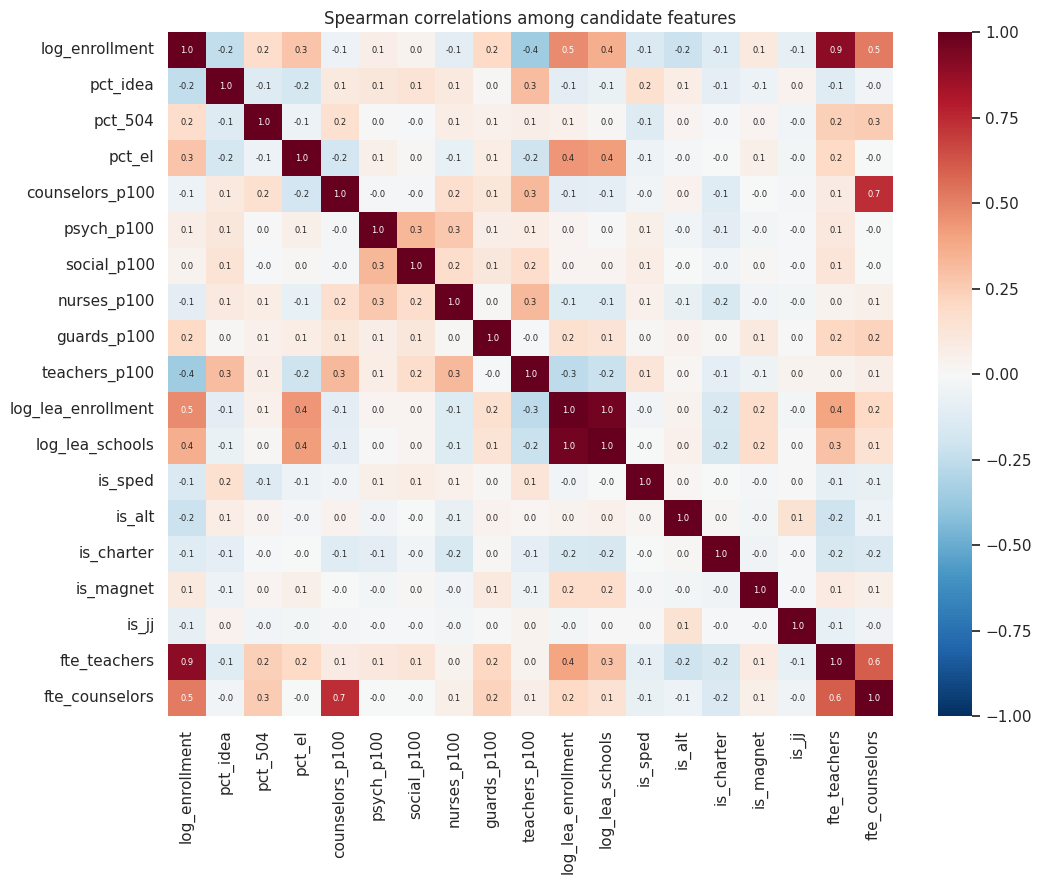

In [31]:
cand = df[df.enr_ge30 & ~df.flag_fte_outlier].copy()
cand['log_enrollment'] = np.log(cand.enrollment_total); cand['log_lea_enrollment'] = np.log(cand.lea_enrollment.clip(lower=1)); cand['log_lea_schools'] = np.log1p(cand.lea_schools)
for c in ['counselors','psych','social','nurses','leo','guards','teachers']:
    cand[f'{c}_p100'] = (cand[f'fte_{c}']/cand.enrollment_total*100); cand[f'{c}_p100'] = cand[f'{c}_p100'].clip(upper=cand[f'{c}_p100'].quantile(.995))
for c in ['sped','alt','charter','magnet','jj']: cand[f'is_{c}'] = cand[f'type_{c}'].astype(int)
feats = ['log_enrollment','pct_idea','pct_504','pct_el','counselors_p100','psych_p100','social_p100','nurses_p100','guards_p100','teachers_p100',
         'log_lea_enrollment','log_lea_schools','is_sped','is_alt','is_charter','is_magnet','is_jj','fte_teachers','fte_counselors']
corr = cand[feats].corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 9)); sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.1f', annot_kws={'size':6}, ax=ax); ax.set_title('Spearman correlations among candidate features'); plt.tight_layout()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename('rho'); pairs = pairs[pairs.abs()>=.5].sort_values(key=abs, ascending=False)
pairs.round(2)

## 13. Leakage review (checklist 13)
2015-16 includes the mechanical and physical restraint counts, so the restraint leakage risk can be measured directly.

In [32]:
from sklearn.metrics import roc_auc_score
r = raw.loc[df.index]
df['phys_inst'] = r[['SCH_RSINSTANCES_PHYS_WODIS','SCH_RSINSTANCES_PHYS_IDEA','SCH_RSINSTANCES_PHYS_504']].sum(axis=1, min_count=3)
df['mech_inst'] = r[['SCH_RSINSTANCES_MECH_WODIS','SCH_RSINSTANCES_MECH_IDEA','SCH_RSINSTANCES_MECH_504']].sum(axis=1, min_count=3)
rows = []
for nm, col in [('physical restraint instances','phys_inst'), ('mechanical restraint instances','mech_inst')]:
    d = df.dropna(subset=[col]); anyr = d[col] > 0
    rows.append({'measure': nm, 'schools_with_valid_value': len(d), 'schools_with_any_restraint_%': anyr.mean()*100,
                 'pct_any_secl | restraint>0': d.loc[anyr,'any_secl'].mean()*100, 'pct_any_secl | restraint=0': d.loc[~anyr,'any_secl'].mean()*100,
                 'spearman_with_secl_instances': d[[col,'seclusion_instances']].corr(method='spearman').iloc[0,1], 'AUC_alone_for_any_secl': roc_auc_score(d.any_secl, d[col])})
d = df.dropna(subset=['phys_inst','mech_inst']); d_ = d.assign(rs=d.phys_inst + d.mech_inst)
rows.append({'measure': 'physical + mechanical', 'schools_with_valid_value': len(d_), 'schools_with_any_restraint_%': (d_.rs>0).mean()*100,
             'pct_any_secl | restraint>0': d_.loc[d_.rs>0,'any_secl'].mean()*100, 'pct_any_secl | restraint=0': d_.loc[d_.rs==0,'any_secl'].mean()*100,
             'spearman_with_secl_instances': d_[['rs','seclusion_instances']].corr(method='spearman').iloc[0,1], 'AUC_alone_for_any_secl': roc_auc_score(d_.any_secl, d_.rs)})
print('For reference, the full non-leaking feature set F (section 14) reaches ROC-AUC ~0.69.')
pd.DataFrame(rows).set_index('measure').round(3)

For reference, the full non-leaking feature set F (section 14) reaches ROC-AUC ~0.69.

,schools_with_valid_value,schools_with_any_restraint_%,pct_any_secl | restraint>0,pct_any_secl | restraint=0,spearman_with_secl_instances,AUC_alone_for_any_secl
measure,,,,,,
physical restraint instances,93966,16.393,26.130,1.451,0.420,0.841
mechanical restraint instances,92255,1.288,22.306,5.381,0.083,0.520
physical + mechanical,92255,17.191,25.706,1.424,0.419,0.844


In [33]:
leak = pd.DataFrame([
 ('SCH_RSINSTANCES_SECL_WODIS / _IDEA / _504 (seclusion_instances_*)', 'DIRECT LEAK', 'Components of the outcome (instances = their sum).'),
 ('seclusion_instances, seclusion_rate_per_100, seclusion_reason*',    'DIRECT LEAK', 'The outcome, its transform, or its missingness reason.'),
 ('TOT_RS_IDEA_SECL_M/F, TOT_RS_NONIDEA_SECL_M/F, secl_students_*_n',  'DIRECT LEAK', 'Number of students secluded (same event, different count). Equity analysis only.'),
 ('SCH_RSINSTANCES_PHYS_* , SCH_RSINSTANCES_MECH_* (restraint)',        'LEAK RISK - exclude', 'Reported in the same CRDC section as seclusion and strongly co-occur (see table above and the AUC jump in section 14).'),
 ('Other discipline (suspensions, expulsions, referrals, arrests)',    'Not in file', 'Not carried through cleaning; same behavioural events. Keep out of the baseline model if added later.'),
 ('fte_leo, fte_guards (security)',                                      'Reverse-causality risk', 'Schools with behaviour problems may hire security. fte_leo is also 73% missing (structural skip) - drop it.'),
 ('flag_missing_seclusion, flag_rate_undefined, *_code, *_reason',       'Exclude', 'Define the sample / describe the outcome; constant in the analysis-ready subset.'),
 ('LEAID, SCHID, COMBOKEY, COMBOKEY_stored, names',                      'Identifier', 'Not features. Use leaid for grouped cross-validation only.'),
], columns=['variable','status','why'])
print(leak.to_string(index=False))
cand_ = cand.copy(); cand_['phys_p100_'] = (df.loc[cand.index,'phys_inst']/cand.enrollment_total*100)
print('\nAbsolute Spearman with any_secl, strongest first (enr>=30, no outliers):')
cc = cand_[feats+['seclusion_instances_idea','seclusion_instances_wodis','seclusion_instances_504','phys_p100_','any_secl']].corr(method='spearman')['any_secl'].drop('any_secl').abs().sort_values(ascending=False); print(cc.round(3).head(12).to_string())

                                                         variable                 status                                                                                                                    why
SCH_RSINSTANCES_SECL_WODIS / _IDEA / _504 (seclusion_instances_*)            DIRECT LEAK                                                                     Components of the outcome (instances = their sum).
   seclusion_instances, seclusion_rate_per_100, seclusion_reason*            DIRECT LEAK                                                                 The outcome, its transform, or its missingness reason.
 TOT_RS_IDEA_SECL_M/F, TOT_RS_NONIDEA_SECL_M/F, secl_students_*_n            DIRECT LEAK                                       Number of students secluded (same event, different count). Equity analysis only.
      SCH_RSINSTANCES_PHYS_* , SCH_RSINSTANCES_MECH_* (restraint)    LEAK RISK - exclude Reported in the same CRDC section as seclusion and strongly co-occur (see table

## 14. Baseline signal check: which feature groups carry information?
Grouped (by district) 5-fold cross-validation so schools of the same district never straddle train/test. Metric: ROC-AUC and average precision (the positive class is only ~6.6%, so AP matters). This is a signal check to inform the shortlist, not a final model.

In [34]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
mdl = cand.dropna(subset=['pct_504','pct_el']).copy()
mdl['idea_suppressed'] = mdl.pct_idea.isna().astype(int)   # 2015-16: IDEA count suppressed for ~11% of schools; keep rows, add indicator
for c in ['fte_leo','fte_guards']: pass
mdl = pd.concat([mdl, pd.get_dummies(mdl.grade_band, prefix='gb', dtype=float)], axis=1)
gb_cols = [c for c in mdl.columns if c.startswith('gb_')]
size = ['log_enrollment']; typ = ['is_sped','is_alt','is_charter','is_magnet','is_jj']+gb_cols
pop = ['pct_idea','pct_504','pct_el','idea_suppressed']; staffc = ['counselors_p100','psych_p100','social_p100','nurses_p100','teachers_p100']; sec = ['guards_p100']
lea = ['log_lea_enrollment','log_lea_schools']
mdl = pd.concat([mdl, pd.get_dummies(mdl.lea_state, prefix='st', dtype=float)], axis=1); st_cols = [c for c in mdl.columns if c.startswith('st_')]
sets = {'A size only': size, 'B + type & grade': size+typ, 'C + population shares': size+typ+pop, 'D + staffing': size+typ+pop+staffc,
        'E + security guards': size+typ+pop+staffc+sec, 'F + district size': size+typ+pop+staffc+sec+lea, 'G + state (one-hot)': size+typ+pop+staffc+sec+lea+st_cols}
y = mdl.any_secl.values; groups = mdl.leaid.values; res = []
for name, cols_ in sets.items():
    pipe = make_pipeline(SimpleImputer(strategy='median'), HistGradientBoostingClassifier(max_iter=150, learning_rate=.08, max_depth=4, random_state=0))
    p = cross_val_predict(pipe, mdl[cols_], y, cv=GroupKFold(5), groups=groups, method='predict_proba')[:,1]
    res.append({'feature set': name, 'n_features': len(cols_), 'ROC_AUC': roc_auc_score(y, p), 'avg_precision': average_precision_score(y, p)})
base = pd.DataFrame(res).set_index('feature set'); print(f'rows={len(mdl):,}; positive rate={y.mean():.3%} (AP baseline = positive rate)'); base.round(3)

rows=90,622; positive rate=5.556% (AP baseline = positive rate)

,n_features,ROC_AUC,avg_precision
feature set,,,
A size only,1,0.553,0.063
B + type & grade,11,0.629,0.088
C + population shares,15,0.661,0.099
D + staffing,20,0.687,0.122
E + security guards,21,0.690,0.124
F + district size,23,0.692,0.119
G + state (one-hot),74,0.802,0.249


In [35]:
# Permutation importance (AUC drop) for the F model on a held-out grouped split
from sklearn.model_selection import GroupShuffleSplit
from sklearn.inspection import permutation_importance
cols_ = sets['F + district size']; tr, te = next(GroupShuffleSplit(1, test_size=.25, random_state=1).split(mdl, y, groups))
pipe = make_pipeline(SimpleImputer(strategy='median'), HistGradientBoostingClassifier(max_iter=150, learning_rate=.08, max_depth=4, random_state=0)).fit(mdl.iloc[tr][cols_], y[tr])
pi = permutation_importance(pipe, mdl.iloc[te][cols_], y[te], scoring='roc_auc', n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=cols_).sort_values(ascending=False); print('held-out AUC:', round(roc_auc_score(y[te], pipe.predict_proba(mdl.iloc[te][cols_])[:,1]),3)); imp.round(4)

held-out AUC: 0.706

,0
log_lea_enrollment,0.050
psych_p100,0.029
gb_high,0.028
teachers_p100,0.022
pct_el,0.017
log_lea_schools,0.017
log_enrollment,0.015
pct_idea,0.013
pct_504,0.009
gb_elementary,0.008


In [36]:
# Leakage demonstration: add restraint counts to the F feature set (NOT recommended - shows how much signal they leak)
mdl['phys_p100'] = (df.loc[mdl.index,'phys_inst']/mdl.enrollment_total*100).clip(upper=100); mdl['mech_p100'] = (df.loc[mdl.index,'mech_inst']/mdl.enrollment_total*100).clip(upper=100)
cols_ = sets['F + district size'] + ['phys_p100','mech_p100']
pipe = make_pipeline(SimpleImputer(strategy='median'), HistGradientBoostingClassifier(max_iter=150, learning_rate=.08, max_depth=4, random_state=0))
p = cross_val_predict(pipe, mdl[cols_], y, cv=GroupKFold(5), groups=groups, method='predict_proba')[:,1]
print(f"F + restraint: ROC-AUC {roc_auc_score(y, p):.3f}, average precision {average_precision_score(y, p):.3f}   (F alone: {base.loc['F + district size','ROC_AUC']:.3f} / {base.loc['F + district size','avg_precision']:.3f})")

F + restraint: ROC-AUC 0.863, average precision 0.381   (F alone: 0.692 / 0.119)

## 15. Data issues found during EDA (checklist deliverable 4)

In [37]:
issues = []
def add(i, sev, issue, n, detail): issues.append({'#': i, 'severity': sev, 'issue': issue, 'rows': n, 'detail': detail})
reg_ = df[df.regular]
no_flag = int(raw.flag_rate_undefined.sum())
add(1,'High','File named "analysis_ready" is not filtered and has no readiness flag', len(raw), f'All 96,360 rows are kept; {no_flag:,} have an undefined rate (missing seclusion or enrollment) and {int(raw.flag_fte_outlier.sum())} are FTE outliers. The 2017-18 file has flag_analysis_ready and a separate filtered file; add the same here so users do not model rows with a missing outcome.')
add(2,'High','IDEA enrollment suppressed (-2) turns idea_n / pct_idea into NA', int(raw.idea_n.isna().sum()), f"{int(raw.idea_n.isna().sum()):,} schools ({raw.idea_n.isna().mean():.1%}) lose idea_n; in {int(((raw.SCH_ENR_IDEA_M.isna()) ^ (raw.SCH_ENR_IDEA_F.isna())).sum()):,} of them one sex is known and only the other is suppressed. The missingness is informative (small schools; about 2.5% report seclusion vs 5.8% when the count is known). Recommend keeping a known sex count as a lower bound, adding idea_suppressed, and not dropping these rows.")
add(3,'High','Impossible shares above 100%', int(sum(n_share_gt100.values())), f'idea_share > 1 in {n_share_gt100["pct_idea"]} schools (max {raw.idea_share.max():.1f}), lep_share > 1 in {n_share_gt100["pct_el"]}. Set to NA here; fix upstream (likely sex-split counts or suppression artefacts) and add a flag.')
add(4,'High','Law-enforcement FTE is unusable', int(raw.SCH_FTESECURITY_LEO.isna().sum()), f'{raw.SCH_FTESECURITY_LEO.isna().mean():.1%} missing (mostly -9 structural skip, concentrated in CA, TX, NY, FL, IL...). Document that fte_leo cannot be used in 2015-16 and is not comparable to 2017-18 (1.7% missing).')
add(5,'High','Meaning of -9 for the seclusion outcome', int((raw.seclusion_reason=='structural_skip').sum()), 'Seclusion is NA for 1,806 schools via -9 (structural skip) and 588 via -5. The same rows are missing for physical restraint, so the whole module was skipped. Confirm with the audit whether -9 means "not applicable / no events" (which would change those NAs to 0 and the prevalence) or "not reported".')
add(6,'Med','Extreme seclusion counts', int((df.seclusion_instances > df.enrollment_total).sum()), f'{int((df.seclusion_instances > df.enrollment_total).sum())} analysis-ready rows have more instances than students; {int((reg_.seclusion_rate>25).sum())} regular (non sped/alt/justice) schools exceed 25 per 100; max {df.seclusion_instances.max():,.0f} instances at one school. Verify the top values against the CRDC source before using them as labels.')
add(7,'Med','Impossible FTE values / outlier flag', int(raw.flag_fte_outlier.sum()), f'flag_fte_outlier fires on {int(raw.flag_fte_outlier.sum())} rows (any FTE > enrollment, or per-100 above 20 / 50 for teachers) but rows are retained; max counselor FTE {raw.SCH_FTECOUNSELORS.max():,.1f}; one school has FTE placeholders of 999 set to NA.')
add(8,'Med','COMBOKEY_stored left in the output', int(raw.COMBOKEY_stored.str.contains("E", na=False).sum()), 'The corrupted scientific-notation key is kept beside the rebuilt one. Drop it (or rename it) to avoid accidental joins.')
add(9,'Med','Schema differs from the 2017-18 file', len(raw.columns), '168 columns (about 100 are *_code / *_reason helpers), upper-case source names, and renamed derived fields (enrollment vs enrollment_total, seclusion_rate_per_100 vs seclusion_rate, idea_share as a 0-1 fraction vs pct_idea in 0-100). Publish one harmonised schema before pooling years.')
add(10,'Med','Small-enrollment flag differs across years', int(raw.flag_small_enrollment.sum()), 'flag_small_enrollment is enrollment < 50 here (5,579 schools) but < 10 in 2017-18; neither is the right cut-off for rates (this EDA recommends 30, see section 9). Use one definition.')
add(11,'Med','grade_band is not provided', 0, 'Derived in this notebook from SCH_GRADE_* flags; the 2017-18 grade_band rules are unknown, so cross-year grade comparisons may be biased. Add grade_band to cleaning with a documented rule.')
add(12,'Med','Race of secluded students and virtual indicator not carried through', 0, 'Required for the equity checklist item (race) and the virtual-school comparison; no virtual indicator exists in the 2015-16 source, so only a name proxy (%d schools) is possible.' % df.type_virtual_name.sum())
add(13,'Low','One school with reserved codes in all flag columns', int((raw.SCH_GRADE_KG == "-5").sum()), 'Yes/No columns contain the string "-5" for one school (enrollment also missing). Recode to NA in YES_NO_COLS.')
add(14,'Low','LEA_ENR missing', int(raw.LEA_ENR.isna().sum()), 'Reserved codes in LEA enrollment; district-size features are NA for these schools.')
add(15,'Low','State coverage', 0, f'{full.lea_state.nunique()} state codes. Hawaii reports zero schools with seclusion, and CA, TX, NV, NY, GA and NC are near or under ~1%: cross-state differences mix real practice with state law and reporting definitions (same pattern as 2017-18).')
pd.DataFrame(issues).set_index('#')

,severity,issue,rows,detail
#,,,,
1,High,"File named ""analysis_ready"" is not filtered and has no readiness flag",96360,"All 96,360 rows are kept; 2,394 have an undefined rate (missing seclusion or enrollment) and 483 are FTE outliers. The 2017-18 file has flag_analysis_ready and a separate filtered file; add the same here so users do not model rows with a missing outcome."
2,High,IDEA enrollment suppressed (-2) turns idea_n / pct_idea into NA,10197,"10,197 schools (10.6%) lose idea_n; in 4,741 of them one sex is known and only the other is suppressed. The missingness is informative (small schools; about 2.5% report seclusion vs 5.8% when the count is known). Recommend keeping a known sex count as a lower bound, adding idea_suppressed, and not dropping these rows."
3,High,Impossible shares above 100%,317,"idea_share > 1 in 299 schools (max 2.0), lep_share > 1 in 18. Set to NA here; fix upstream (likely sex-split counts or suppression artefacts) and add a flag."
4,High,Law-enforcement FTE is unusable,70937,"73.6% missing (mostly -9 structural skip, concentrated in CA, TX, NY, FL, IL...). Document that fte_leo cannot be used in 2015-16 and is not comparable to 2017-18 (1.7% missing)."
5,High,Meaning of -9 for the seclusion outcome,1806,"Seclusion is NA for 1,806 schools via -9 (structural skip) and 588 via -5. The same rows are missing for physical restraint, so the whole module was skipped. Confirm with the audit whether -9 means ""not applicable / no events"" (which would change those NAs to 0 and the prevalence) or ""not reported""."
6,Med,Extreme seclusion counts,135,"135 analysis-ready rows have more instances than students; 191 regular (non sped/alt/justice) schools exceed 25 per 100; max 3,088 instances at one school. Verify the top values against the CRDC source before using them as labels."
7,Med,Impossible FTE values / outlier flag,483,"flag_fte_outlier fires on 483 rows (any FTE > enrollment, or per-100 above 20 / 50 for teachers) but rows are retained; max counselor FTE 550.5; one school has FTE placeholders of 999 set to NA."
8,Med,COMBOKEY_stored left in the output,78034,The corrupted scientific-notation key is kept beside the rebuilt one. Drop it (or rename it) to avoid accidental joins.
9,Med,Schema differs from the 2017-18 file,168,"168 columns (about 100 are *_code / *_reason helpers), upper-case source names, and renamed derived fields (enrollment vs enrollment_total, seclusion_rate_per_100 vs seclusion_rate, idea_share as a 0-1 fraction vs pct_idea in 0-100). Publish one harmonised schema before pooling years."


## 16. Key findings (2015-16)
1. **Data match the audit and are more complete than 2017-18.** All 11 audit counts reproduce exactly. 93,966 of 96,360 schools (97.5%) have a valid outcome; 2,394 (2.5%) are missing it (1,806 structural skips, -9; 588 missing, -5) versus 6.8% in 2017-18. The dropped schools are small (median 161 students vs 449), more often special-education (11.6% vs 2.0%) and have double the %IDEA, so the analysis set under-represents the highest-risk schools. The file has no readiness flag, so the analysis-ready subset must be derived (`~flag_rate_undefined`).
2. **Seclusion is rare and extremely skewed.** 94.5% of schools report zero; 5.50% (5,165) report at least one instance (6.56% in 2017-18). Among those, the median is 4 instances, the 90th percentile 50 and the maximum 3,088. The top 100 schools hold 39.8% of all instances (30% in 2017-18).
3. **State reporting context dominates.** Wisconsin, Maine, Iowa, Connecticut, Vermont and Kansas have 16-28% of schools reporting any seclusion; California, Texas, Nevada and New York are around 1% or below and Hawaii reports none. State alone gives ROC-AUC 0.79, and adding it to the baseline model lifts average precision from 0.12 to 0.25.
4. **Concentrated in few districts.** 12.2% of districts have any school reporting seclusion; 70 districts hold half of all instances and 291 hold 80%. A handful of single-district clusters dominate (York City SD, PA; Centralia SD, WA; Des Moines, IA; GA Department of Juvenile Justice).
5. **School type.** Special-education schools: 15.2% report any (vs 5.3%) and hold 21.8% of instances while being about 2% of schools; justice facilities 6.7%; alternative 2.5%, charter 2.7%, magnet 3.8%; the name-proxy virtual group 0.3%. Elementary 7.4%, span 5.4%, middle 4.3%, high 2.5%. 93% of positive schools are ordinary schools.
6. **Student population.** %IDEA is the clearest positive correlate (2.0% any when under 5% IDEA, 6.7% at 15-20%, flat above 20%). %504 is negative at 5% and above; %EL is inverted-U. All rank correlations with the outcome are weak (|rho| <= 0.05). The IDEA count is suppressed (-2) for 10.6% of schools, and that suppression is informative: those schools are small and rarely report seclusion (2.5% vs 5.8%).
7. **Staffing.** Non-monotonic and confounded by school size and need. Psychologists and social workers are positively associated after adjustment; security guards negative; counselors and nurses add almost nothing. Law-enforcement FTE is 73.6% missing (structural skip) and is unusable. Staffing may respond to behaviour problems, so these are associations.
8. **Small enrollments distort rates.** Schools under 30 students are 3.4% of schools and 2.2% of instances but 30% of schools with rates above 100 per 100 students. Median rate among positives is 41 for enrollments of 1-9 and 17 for 30-99, versus 1.4 for 250-499. Use a minimum enrollment of 30 plus shrinkage (k about 30-100).
9. **Across years (2015-16 vs 2017-18, 86,019 schools in both).** Prevalence rose from 5.65% to 6.74% in the matched set. Seclusion is persistent: 47.2% of schools with any in 2015-16 also have any in 2017-18, versus 4.3% of those with none; 39.5% of 2017-18 positives were already positive. State prevalence is nearly identical across years (r = 0.97), so state differences are structural rather than year noise.
10. **Equity (sex and disability).** Boys are 77% of secluded students. Students with IDEA are 12.7% of enrolled students in the valid rows but 68.6% of secluded students: 0.40 secluded students per 100 vs 0.026 for others (15x). IDEA boys 0.475 per 100 vs 0.015 for non-IDEA girls (31x). Students secluded under IDEA were secluded 4.1 times on average vs 1.9 for others. Race could not be assessed (not in the cleaned file).
11. **Leakage.** The three seclusion components, the rate, and secluded-student counts are the outcome. Physical restraint instances are a strong leak: 26.1% of schools with restraint report seclusion vs 1.4% without (AUC 0.84 alone), and adding restraint to the baseline raises ROC-AUC from 0.69 to 0.86 and average precision from 0.12 to 0.38. Mechanical restraint is rare (1.3%) and a weak predictor but belongs to the same module. Exclude both.
12. **Redundant features.** District enrollment and district school count (rho 0.96); school enrollment and teacher FTE (0.89); counselors per 100 and counselor FTE (0.74).

## 17. Recommended target definition
| | Definition | Prevalence | Use |
|---|---|---|---|
| **Primary: `any_seclusion`** | `seclusion_instances >= 1` | 5.5% of analysis-ready schools | Main classification target. Robust to enrollment, avoids the unstable rate. |
| **Secondary: `elevated_seclusion`** | `seclusion_instances >= 5` **and** `seclusion_rate_per_100 >= 1` | 2.5% of schools with enrollment >= 30 | Sensitivity analysis. Five instances covers 96% of all instances and removes one-off events; the rate floor stops large schools qualifying on volume alone. |
| Not recommended | Raw rate or raw count as regression target | | 94.5% zeros, heavy tail (max 3,057 per 100), denominator-driven for small schools. |

These are the same definitions recommended for 2017-18, so models can be compared or pooled across years. **Modeling frame:** `~flag_rate_undefined`, enrollment >= 30 (drops 3,212 schools, 3.4%), exclude `flag_fte_outlier` rows, grouped cross-validation by `LEAID`. Keep schools with suppressed IDEA counts and add an `idea_suppressed` indicator rather than dropping them. If years are pooled, add a year indicator and treat -9 consistently (see data issue 5).

In [38]:
shortlist = pd.DataFrame([
 ('log(enrollment)', 'Size', 'Include', 'Scale effect; instances scale with students.'),
 ('grade_band (derived)', 'School type', 'Include', 'Elementary 7.4% vs high 2.5% any seclusion; holds in regular schools. Needs a documented upstream rule.'),
 ('flag_sped', 'School type', 'Include', '15.2% vs 5.3% any; 21.8% of instances.'),
 ('flag_alt', 'School type', 'Include', 'Lower rate, distinct population.'),
 ('flag_charter', 'School type', 'Include', '2.7% vs 5.7% any.'),
 ('flag_jj', 'School type', 'Include', 'Small group (608) but extreme counts when positive.'),
 ('flag_magnet', 'School type', 'Optional', 'Weak permutation importance.'),
 ('idea_share (pct_idea)', 'Population', 'Include', 'Clearest positive correlate. Values above 100% set to NA.'),
 ('idea_suppressed (new indicator)', 'Population', 'Include', 'IDEA count suppressed for 10.6% of schools; informative missingness (small schools, low rates).'),
 ('sec504_share, lep_share', 'Population', 'Include', '504 negative at high levels; EL inverted-U; weak but independent of IDEA.'),
 ('psych per 100, social per 100', 'Staffing', 'Include', 'Positive association after adjustment; cap per-100 ratios at the 99.5th percentile.'),
 ('counselors per 100, nurses per 100', 'Staffing', 'Optional', 'Near-zero adjusted effect.'),
 ('teachers per 100', 'Staffing', 'Optional', 'Moderate importance but unstable for tiny schools.'),
 ('guards per 100', 'Security', 'Optional (caution)', 'Negative association; likely reverse causality.'),
 ('log(LEA_ENR)', 'District context', 'Include', 'Top permutation importance among context features; drop LEA_SCHOOLS (rho 0.96).'),
 ('LEA_STATE (categorical / region)', 'Context', 'Include in a second model', 'Dominant signal (AUC 0.69 -> 0.80); reflects state law and reporting practice. Run with and without.'),
 ('SCH_FTESECURITY_LEO (law enforcement FTE)', 'Security', 'Drop', '73.6% missing (structural skip), concentrated in the largest states.'),
 ('SCH_FTETEACH_TOT, SCH_FTECOUNSELORS (raw counts)', 'Staffing', 'Drop', 'Redundant with enrollment (rho 0.89 / 0.52).'),
 ('LEA_SCHOOLS', 'District context', 'Drop', 'rho 0.96 with log(LEA_ENR).'),
 ('SCH_RSINSTANCES_SECL_*, seclusion_instances, seclusion_rate_per_100, TOT_RS_*_SECL_*, secl_students_*', 'Outcome', 'EXCLUDE (leak)', 'Components or transforms of the target.'),
 ('SCH_RSINSTANCES_PHYS_*, SCH_RSINSTANCES_MECH_*', 'Restraint', 'EXCLUDE (leak)', 'Measured: AUC 0.84 alone; raises baseline AUC from 0.69 to 0.86.'),
 ('COMBOKEY_stored, *_code, *_reason, flag_missing_*', 'Helper', 'Not features', 'Corrupted key / reserved-code bookkeeping.'),
 ('LEAID, SCHID, COMBOKEY, names', 'Identifier', 'Not features', 'Use LEAID for grouped CV only.'),
], columns=['feature','group','decision','reason'])
shortlist

,feature,group,decision,reason
0,log(enrollment),Size,Include,Scale effect; instances scale with students.
1,grade_band (derived),School type,Include,Elementary 7.4% vs high 2.5% any seclusion; holds in regular schools. Needs a documented upstream rule.
2,flag_sped,School type,Include,15.2% vs 5.3% any; 21.8% of instances.
3,flag_alt,School type,Include,"Lower rate, distinct population."
4,flag_charter,School type,Include,2.7% vs 5.7% any.
5,flag_jj,School type,Include,Small group (608) but extreme counts when positive.
6,flag_magnet,School type,Optional,Weak permutation importance.
7,idea_share (pct_idea),Population,Include,Clearest positive correlate. Values above 100% set to NA.
8,idea_suppressed (new indicator),Population,Include,"IDEA count suppressed for 10.6% of schools; informative missingness (small schools, low rates)."
9,"sec504_share, lep_share",Population,Include,504 negative at high levels; EL inverted-U; weak but independent of IDEA.


In [39]:
OUT_DIR = Path('/mnt/user-data/outputs'); OUT_DIR.mkdir(parents=True, exist_ok=True)
shortlist.to_csv(OUT_DIR/'feature_shortlist_201516.csv', index=False)
pd.DataFrame(issues).to_csv(OUT_DIR/'data_issues_201516.csv', index=False)
frame = df[(df.enrollment_total >= 30) & ~df.flag_fte_outlier].copy()
frame['elevated_seclusion'] = ((frame.seclusion_instances >= 5) & (frame.seclusion_rate >= 1)).astype(int)
print(f"Modeling frame: {len(frame):,} schools | any_seclusion prevalence {frame.any_secl.mean():.2%} | elevated_seclusion prevalence {frame.elevated_seclusion.mean():.2%} ({frame.elevated_seclusion.sum():,} schools)")

Modeling frame: 90,637 schools | any_seclusion prevalence 5.56% | elevated_seclusion prevalence 2.53% (2,296 schools)